# Objective:

### The increasing number of cancellations calls for a Machine Learning based solution that can help in predicting which bookings are likely to be canceled. INN Hotels Group has a chain of hotels in Portugal, and they are facing problems with the high number of booking cancellations and have reached out to your firm for data-driven solutions. As a data scientist analyze the data provided to find which factors have a high influence on booking cancellations, build a predictive model that can predict which bookings are going to be canceled in advance, and help in formulating profitable policies for cancellations and refunds.



# Data Processing

In [1]:
import warnings
warnings.filterwarnings("ignore")

# Libraries to help with reading and manipulating data
import pandas as pd
import numpy as np

# libaries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Removes the limit for the number of displayed columns
pd.set_option("display.max_columns", None)
# Sets the limit for the number of displayed rows
pd.set_option("display.max_rows", 200)
# setting the precision of floating numbers to 5 decimal points
pd.set_option("display.float_format", lambda x: "%.5f" % x)

# Library to split data
from sklearn.model_selection import train_test_split

# To build model for prediction
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree

# To tune different models
from sklearn.model_selection import GridSearchCV

# To get diferent metric scores
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    recall_score,
    precision_score,
    confusion_matrix,
    make_scorer,
    roc_curve,
    roc_auc_score,
)

In [2]:
data = pd.read_csv('/content/drive/MyDrive/PGP_DSA/Projects/Classification Techniques for Predictive Modeling/INNHotelsGroup.csv')
df = data.copy()

In [3]:
df.head()

,Booking_ID,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,INN00001,2,0,1,2,Meal Plan 1,0,Room_Type 1,224,2017,10,2,Offline,0,0,0,65.00000,0,Not_Canceled
1,INN00002,2,0,2,3,Not Selected,0,Room_Type 1,5,2018,11,6,Online,0,0,0,106.68000,1,Not_Canceled
2,INN00003,1,0,2,1,Meal Plan 1,0,Room_Type 1,1,2018,2,28,Online,0,0,0,60.00000,0,Canceled
3,INN00004,2,0,0,2,Meal Plan 1,0,Room_Type 1,211,2018,5,20,Online,0,0,0,100.00000,0,Canceled
4,INN00005,2,0,1,1,Not Selected,0,Room_Type 1,48,2018,4,11,Online,0,0,0,94.50000,0,Canceled


In [4]:
df.tail()

,Booking_ID,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
36270,INN36271,3,0,2,6,Meal Plan 1,0,Room_Type 4,85,2018,8,3,Online,0,0,0,167.80000,1,Not_Canceled
36271,INN36272,2,0,1,3,Meal Plan 1,0,Room_Type 1,228,2018,10,17,Online,0,0,0,90.95000,2,Canceled
36272,INN36273,2,0,2,6,Meal Plan 1,0,Room_Type 1,148,2018,7,1,Online,0,0,0,98.39000,2,Not_Canceled
36273,INN36274,2,0,0,3,Not Selected,0,Room_Type 1,63,2018,4,21,Online,0,0,0,94.50000,0,Canceled
36274,INN36275,2,0,1,2,Meal Plan 1,0,Room_Type 1,207,2018,12,30,Offline,0,0,0,161.67000,0,Not_Canceled


In [5]:
df.shape

(36275, 19)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36275 entries, 0 to 36274
Data columns (total 19 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Booking_ID                            36275 non-null  object 
 1   no_of_adults                          36275 non-null  int64  
 2   no_of_children                        36275 non-null  int64  
 3   no_of_weekend_nights                  36275 non-null  int64  
 4   no_of_week_nights                     36275 non-null  int64  
 5   type_of_meal_plan                     36275 non-null  object 
 6   required_car_parking_space            36275 non-null  int64  
 7   room_type_reserved                    36275 non-null  object 
 8   lead_time                             36275 non-null  int64  
 9   arrival_year                          36275 non-null  int64  
 10  arrival_month                         36275 non-null  int64  
 11  arrival_date   

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
no_of_adults,36275.00000,1.84496,0.51871,0.00000,2.00000,2.00000,2.00000,4.00000
no_of_children,36275.00000,0.10528,0.40265,0.00000,0.00000,0.00000,0.00000,10.00000
no_of_weekend_nights,36275.00000,0.81072,0.87064,0.00000,0.00000,1.00000,2.00000,7.00000
no_of_week_nights,36275.00000,2.20430,1.41090,0.00000,1.00000,2.00000,3.00000,17.00000
required_car_parking_space,36275.00000,0.03099,0.17328,0.00000,0.00000,0.00000,0.00000,1.00000
lead_time,36275.00000,85.23256,85.93082,0.00000,17.00000,57.00000,126.00000,443.00000
arrival_year,36275.00000,2017.82043,0.38384,2017.00000,2018.00000,2018.00000,2018.00000,2018.00000
arrival_month,36275.00000,7.42365,3.06989,1.00000,5.00000,8.00000,10.00000,12.00000
arrival_date,36275.00000,15.59700,8.74045,1.00000,8.00000,16.00000,23.00000,31.00000
repeated_guest,36275.00000,0.02564,0.15805,0.00000,0.00000,0.00000,0.00000,1.00000


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.nunique()

,0
Booking_ID,36275
no_of_adults,5
no_of_children,6
no_of_weekend_nights,8
no_of_week_nights,18
type_of_meal_plan,4
required_car_parking_space,2
room_type_reserved,7
lead_time,352
arrival_year,2


In [10]:
df.isnull().sum()

,0
Booking_ID,0
no_of_adults,0
no_of_children,0
no_of_weekend_nights,0
no_of_week_nights,0
type_of_meal_plan,0
required_car_parking_space,0
room_type_reserved,0
lead_time,0
arrival_year,0




---



# Exploratory Data Analysis

## Univariate Analysis

Categorical Variables

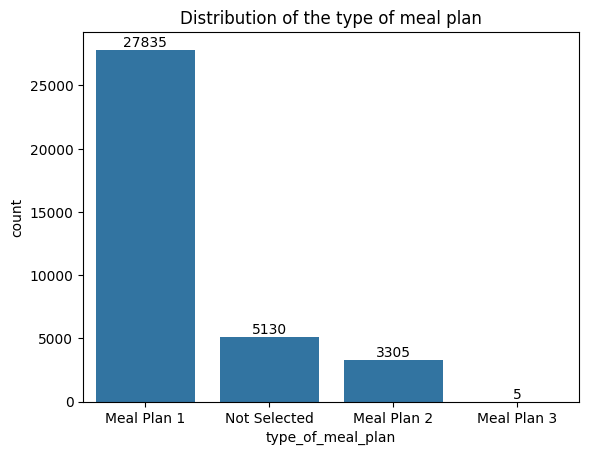

In [11]:
ax = sns.countplot(data = df, x = 'type_of_meal_plan')
for container in ax.containers:
    ax.bar_label(container)

plt.title('Distribution of the type of meal plan');

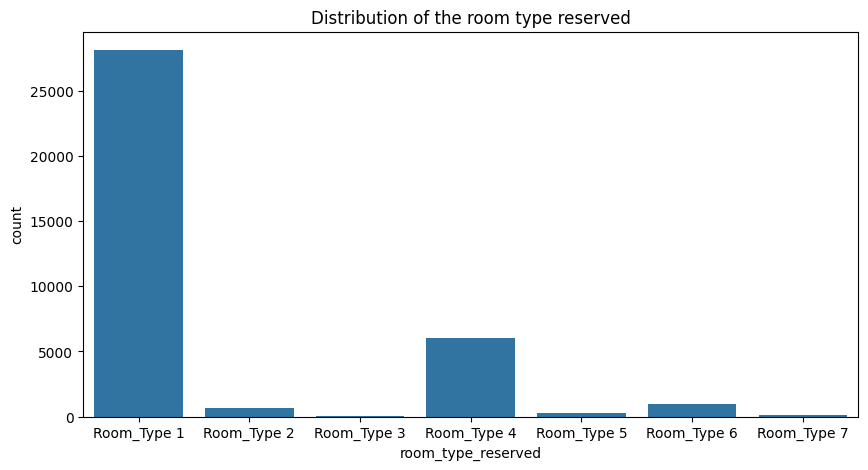

In [12]:
ordered_room_types = sorted(df['room_type_reserved'].unique())

plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='room_type_reserved', order=ordered_room_types)
plt.title('Distribution of the room type reserved');

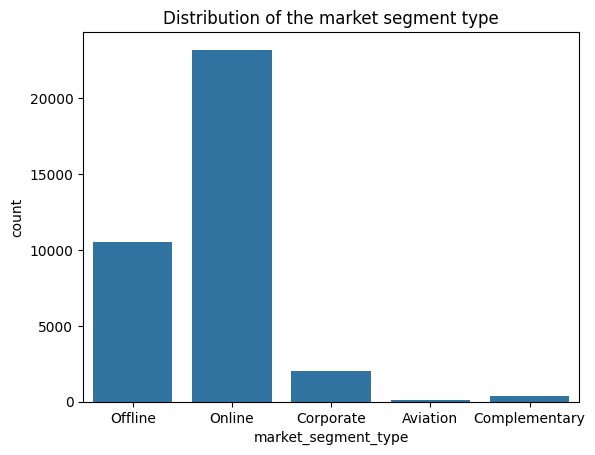

In [13]:
sns.countplot(data = df, x = 'market_segment_type')
plt.title('Distribution of the market segment type');

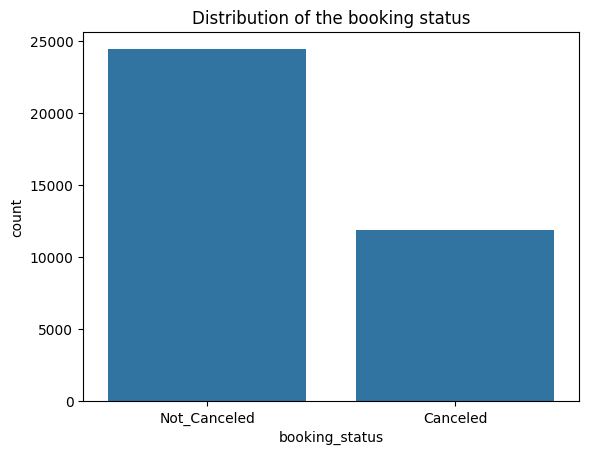

In [14]:
sns.countplot(data = df, x = 'booking_status')
plt.title('Distribution of the booking status');

Numerical Variables

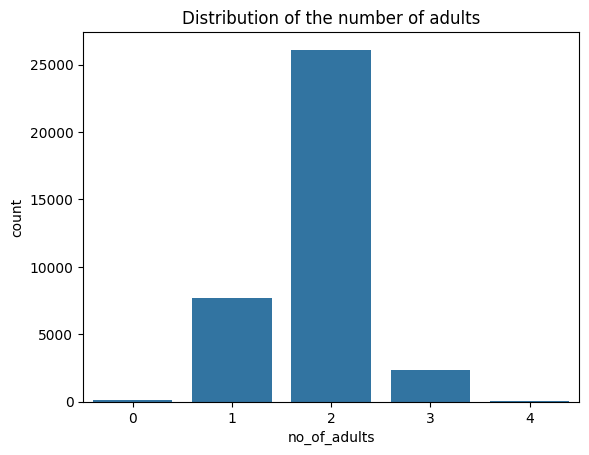

In [15]:
sns.countplot(data = df, x = 'no_of_adults')
plt.title('Distribution of the number of adults');

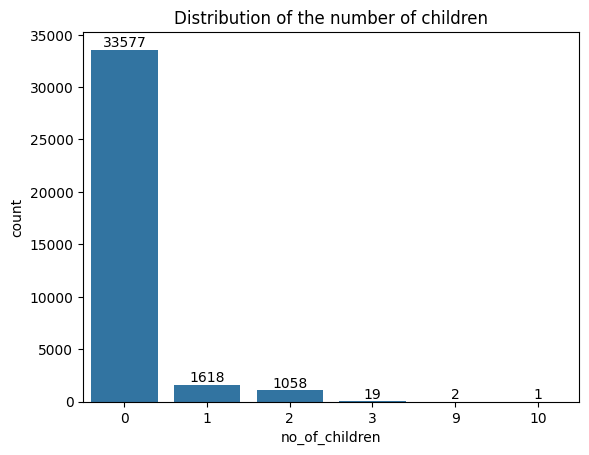

In [16]:
ax = sns.countplot(data = df, x = 'no_of_children')
for container in ax.containers:
    ax.bar_label(container)

plt.title('Distribution of the number of children');

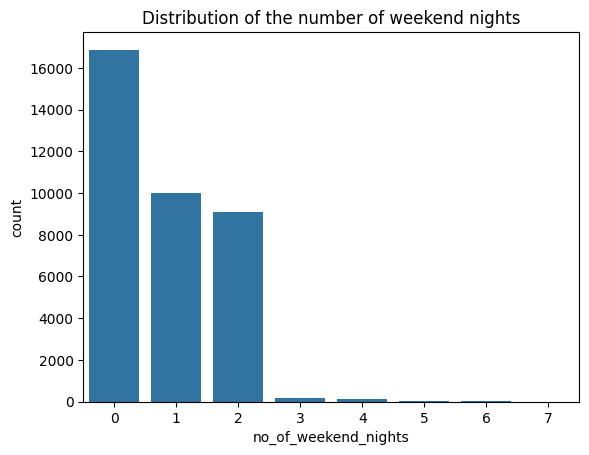

In [17]:
sns.countplot(data = df, x = 'no_of_weekend_nights')
plt.title('Distribution of the number of weekend nights');

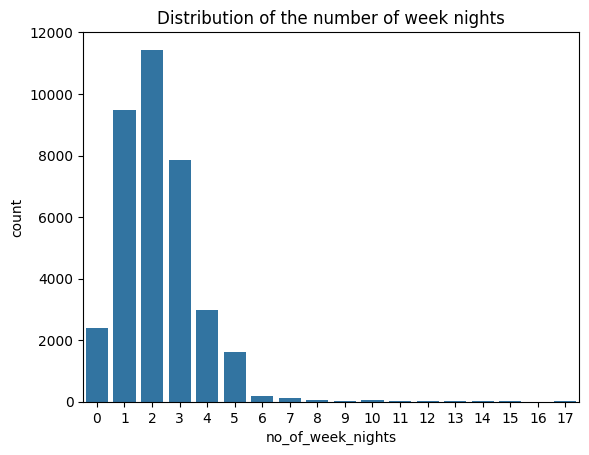

In [18]:
sns.countplot(data = df, x = 'no_of_week_nights')
plt.title('Distribution of the number of week nights');

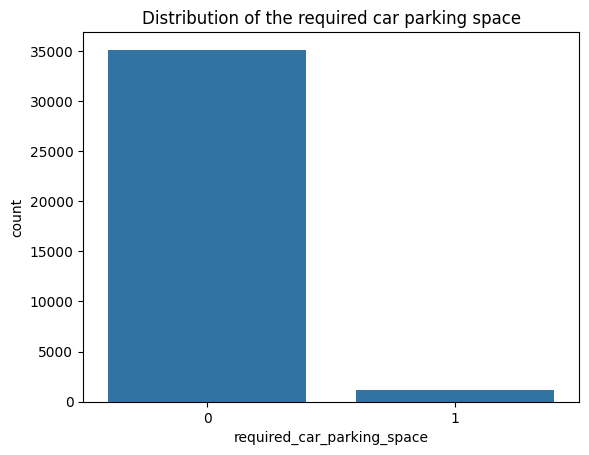

In [19]:
sns.countplot(data = df, x = 'required_car_parking_space')
plt.title('Distribution of the required car parking space');

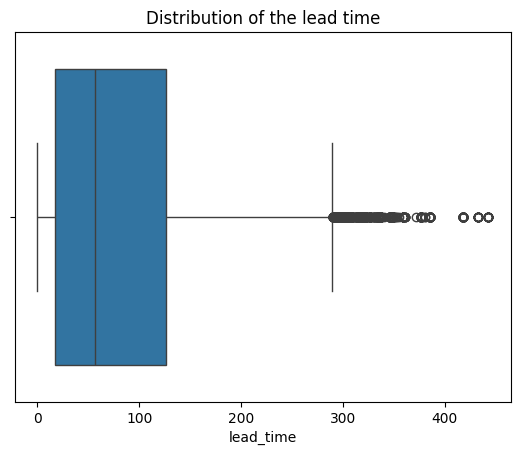

In [20]:
sns.boxplot(data = df, x = 'lead_time')
plt.title('Distribution of the lead time');

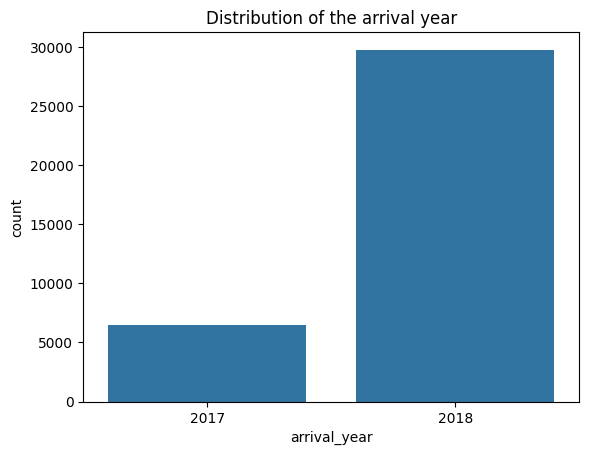

In [21]:
sns.countplot(data = df, x = 'arrival_year')
plt.title('Distribution of the arrival year');

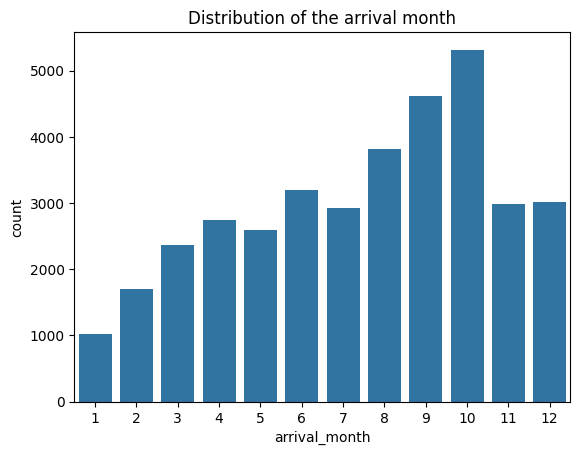

In [22]:
sns.countplot(data = df, x = 'arrival_month')
plt.title('Distribution of the arrival month');

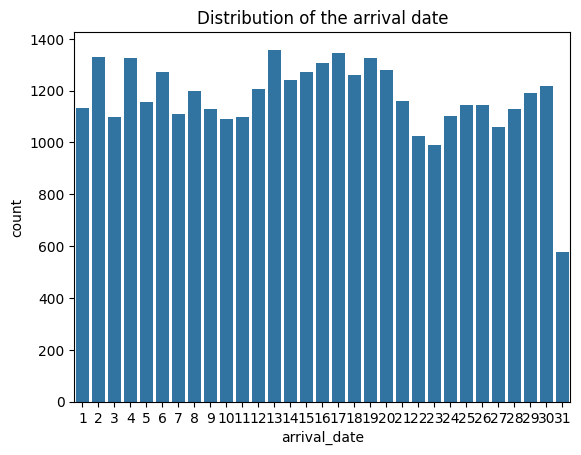

In [23]:
sns.countplot(data = df, x = 'arrival_date')
plt.title('Distribution of the arrival date');

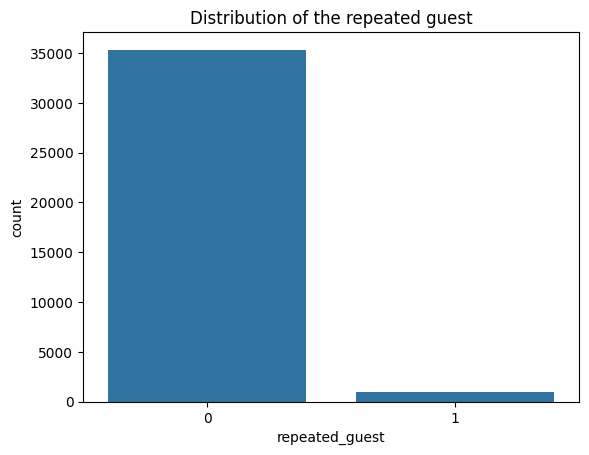

In [24]:
sns.countplot(data = df, x = 'repeated_guest')
plt.title('Distribution of the repeated guest');

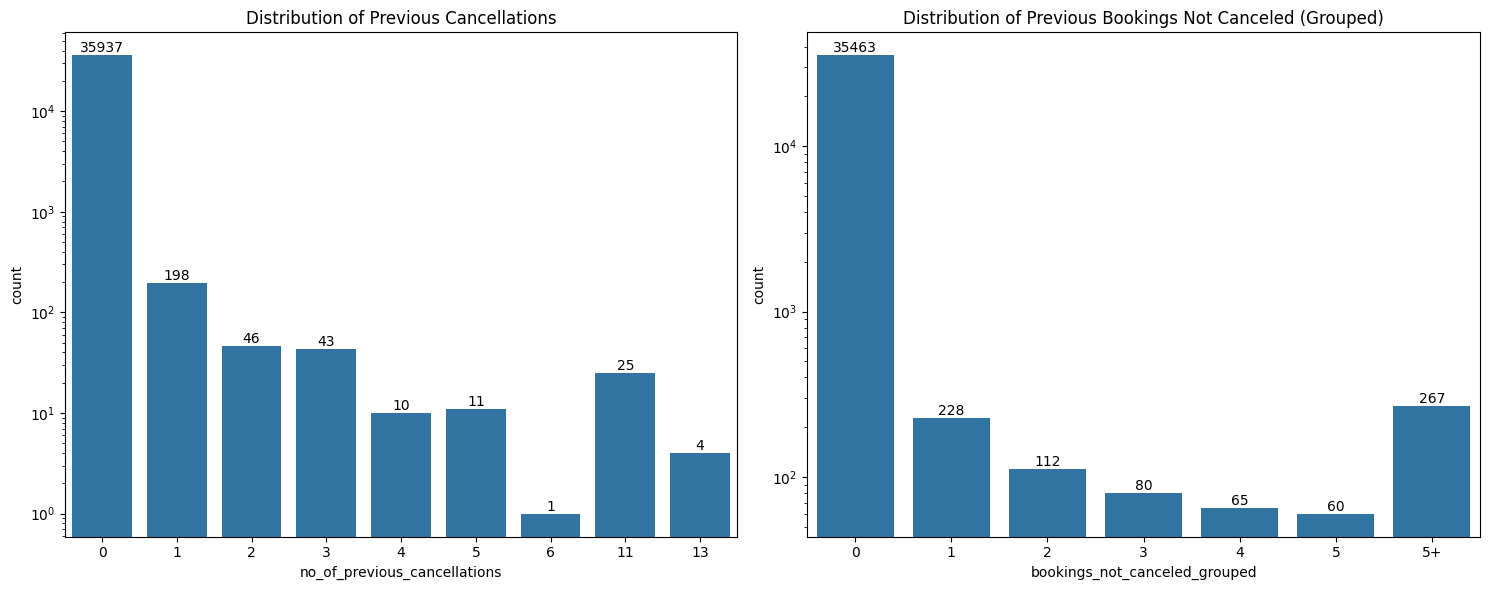

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

# Left Plot: Previous Cancellations
sns.countplot(data=df, x='no_of_previous_cancellations', ax=ax[0])
ax[0].set_title('Distribution of Previous Cancellations')
ax[0].set_yscale('log') # Log scale to better visualize rare non-zero counts
for container in ax[0].containers:
    ax[0].bar_label(container)

# Right Plot: Previous Bookings Not Canceled
# We group values greater than 5 into '5+' for a cleaner visualization
df_temp = df.copy()
df_temp['bookings_not_canceled_grouped'] = df_temp['no_of_previous_bookings_not_canceled'].apply(lambda x: str(x) if x <= 5 else '5+')
ordered_labels = [str(i) for i in range(6)] + ['5+']

sns.countplot(data=df_temp, x='bookings_not_canceled_grouped', order=ordered_labels, ax=ax[1])
ax[1].set_title('Distribution of Previous Bookings Not Canceled (Grouped)')
ax[1].set_yscale('log') # Log scale for better visibility
for container in ax[1].containers:
    ax[1].bar_label(container)

plt.tight_layout()
plt.show()

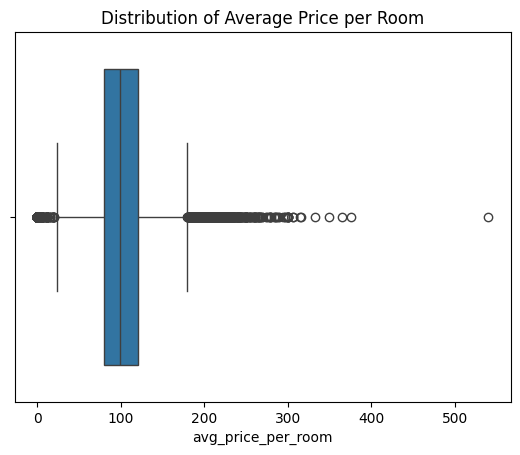

In [26]:
sns.boxplot(data=df, x='avg_price_per_room')
plt.title('Distribution of Average Price per Room');

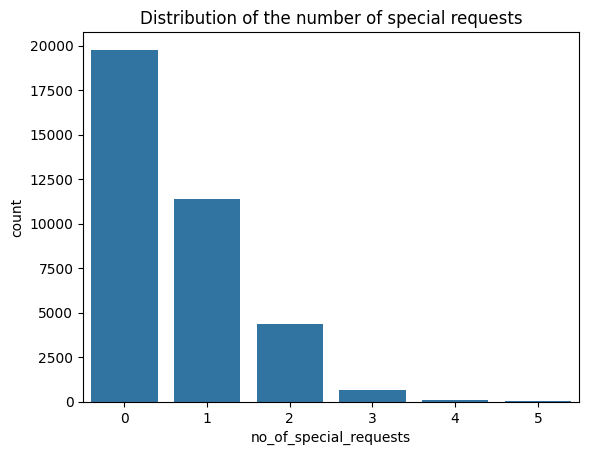

In [27]:
sns.countplot(data = df, x = 'no_of_special_requests')
plt.title('Distribution of the number of special requests');

## Bivariate Analysis

### Numerical Variables vs Booking Status

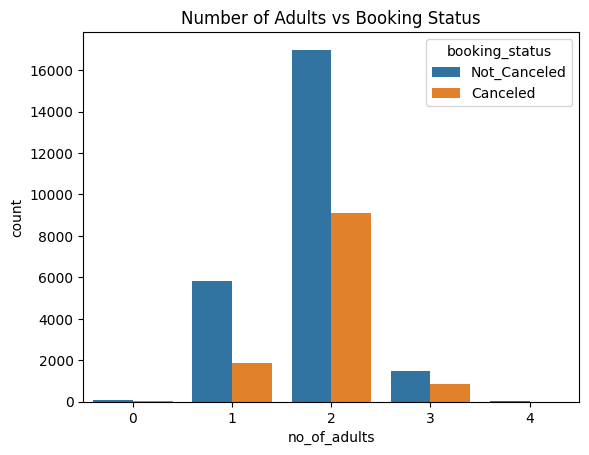

In [28]:
sns.countplot(data = df, x = 'no_of_adults', hue = 'booking_status')
plt.title('Number of Adults vs Booking Status');

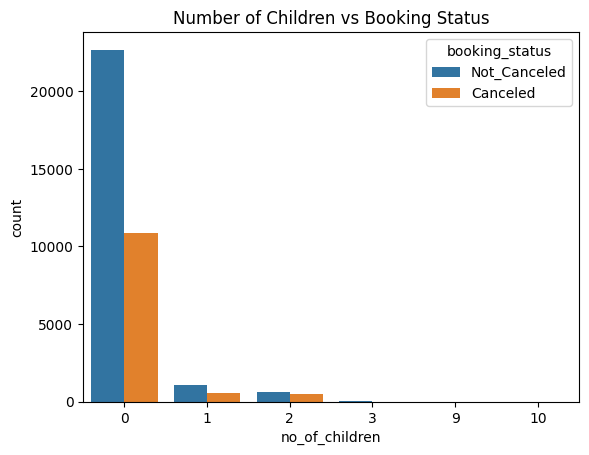

In [29]:
sns.countplot(data = df, x = 'no_of_children', hue = 'booking_status')
plt.title('Number of Children vs Booking Status');

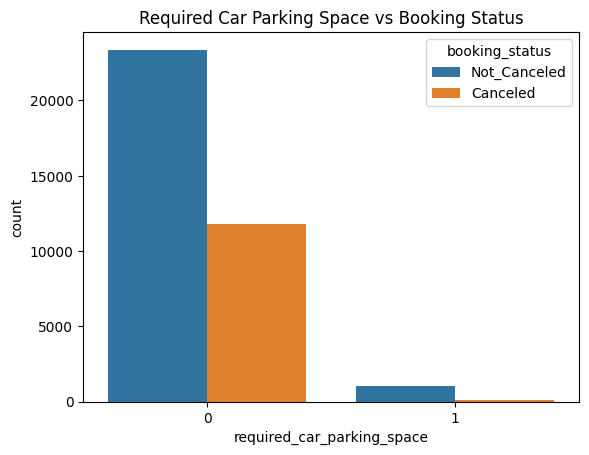

In [30]:
sns.countplot(data = df, x = 'required_car_parking_space', hue = 'booking_status')
plt.title('Required Car Parking Space vs Booking Status');

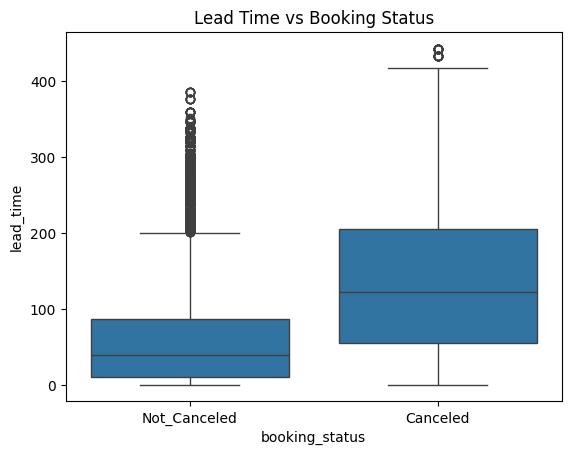

In [31]:
sns.boxplot(data=df, x='booking_status', y='lead_time')
plt.title('Lead Time vs Booking Status');

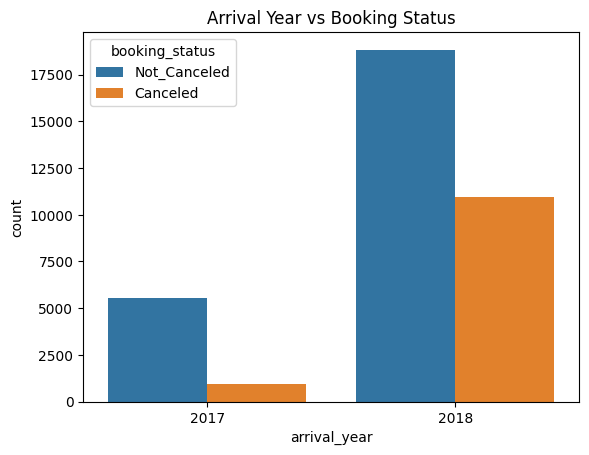

In [32]:
sns.countplot(data = df, x = 'arrival_year', hue = 'booking_status')
plt.title('Arrival Year vs Booking Status');

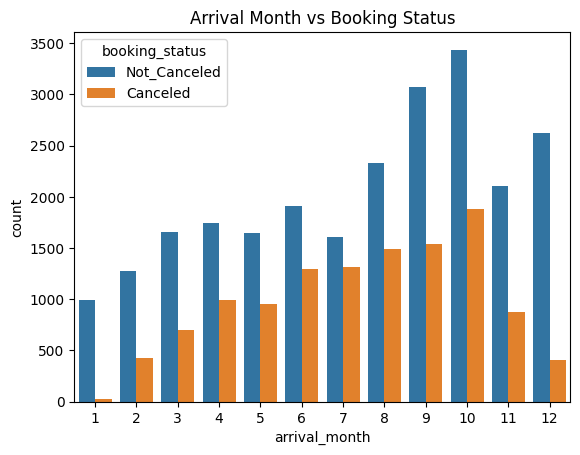

In [33]:
sns.countplot(data = df, x = 'arrival_month', hue = 'booking_status')
plt.title('Arrival Month vs Booking Status');

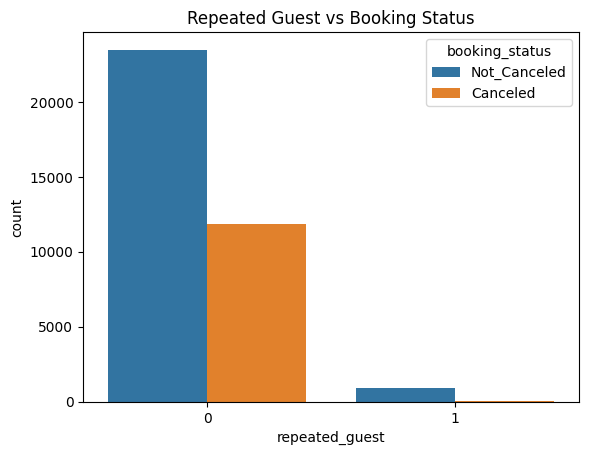

In [34]:
sns.countplot(data = df, x = 'repeated_guest', hue = 'booking_status')
plt.title('Repeated Guest vs Booking Status');

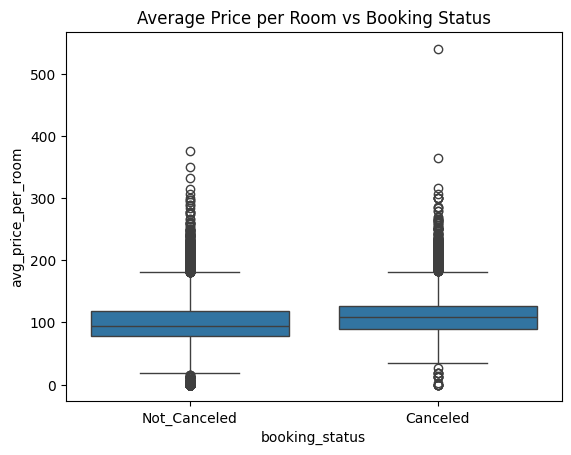

In [35]:
sns.boxplot(data=df, x='booking_status', y='avg_price_per_room')
plt.title('Average Price per Room vs Booking Status');

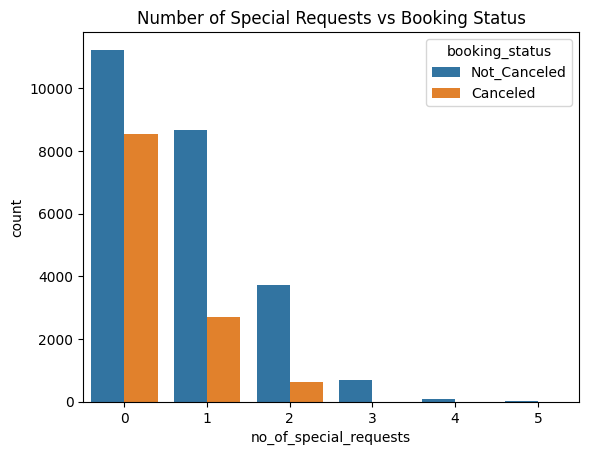

In [36]:
sns.countplot(data = df, x = 'no_of_special_requests', hue = 'booking_status')
plt.title('Number of Special Requests vs Booking Status');

### Categorical Variables vs Booking Status

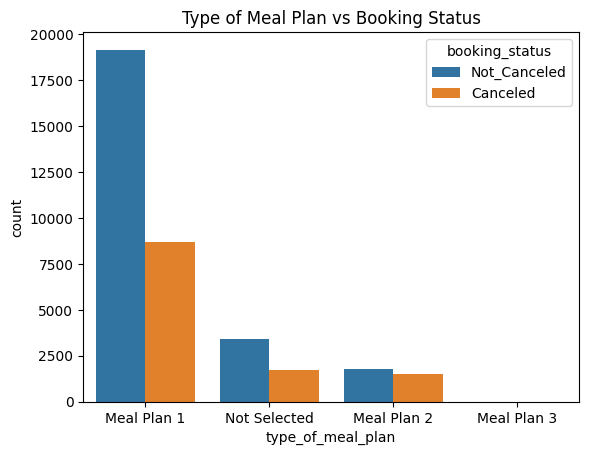

In [37]:
sns.countplot(data = df, x = 'type_of_meal_plan', hue = 'booking_status')
plt.title('Type of Meal Plan vs Booking Status');

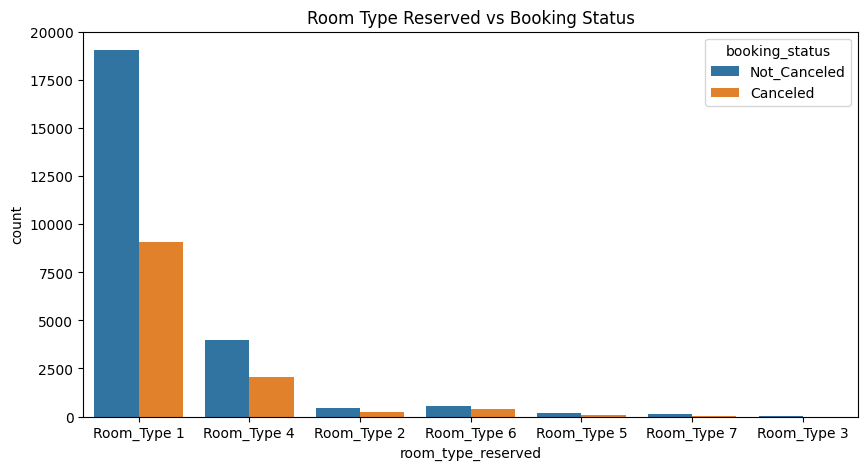

In [38]:
plt.figure(figsize=(10, 5))
sns.countplot(data = df, x = 'room_type_reserved', hue = 'booking_status')
plt.title('Room Type Reserved vs Booking Status');

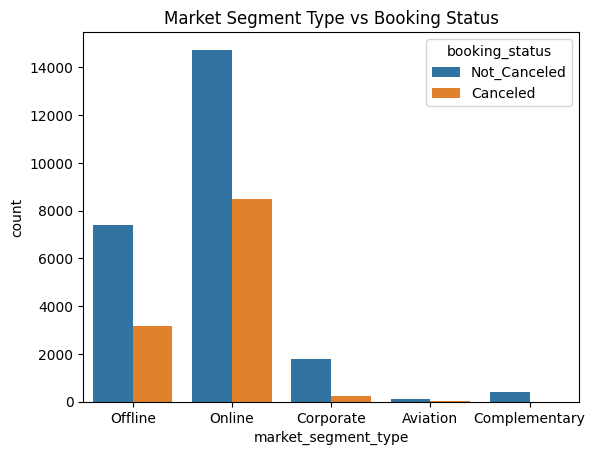

In [39]:
sns.countplot(data = df, x = 'market_segment_type', hue = 'booking_status')
plt.title('Market Segment Type vs Booking Status');

## Key Questions:

### 1. What are the busiest months in the hotel?

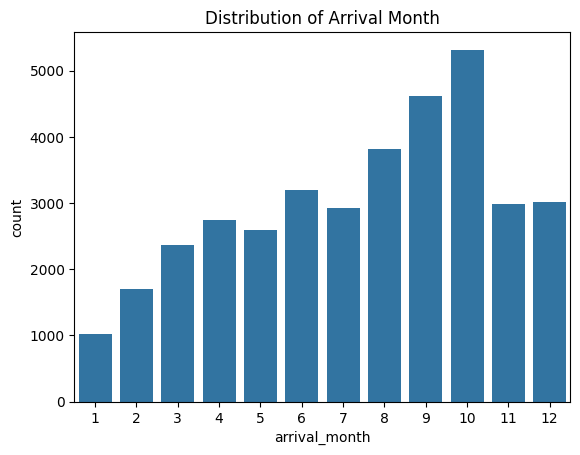

In [40]:
sns.countplot(data = df, x = 'arrival_month')
plt.title('Distribution of Arrival Month');

### 2. Which market segment do most of the guests come from?

In [41]:
df['market_segment_type'].value_counts()

,count
market_segment_type,
Online,23214
Offline,10528
Corporate,2017
Complementary,391
Aviation,125


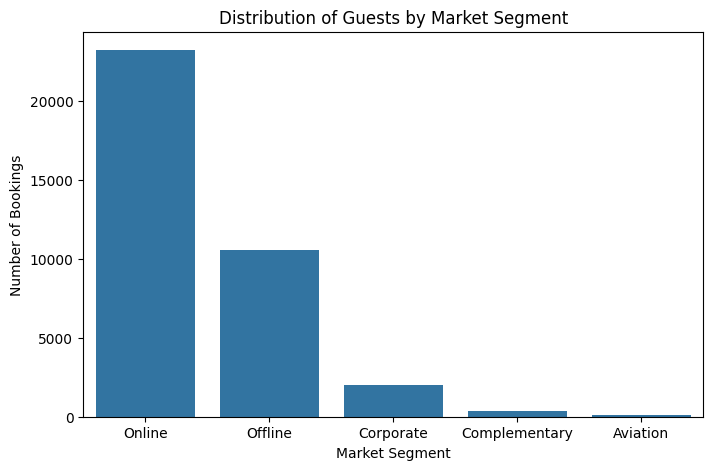

In [42]:
plt.figure(figsize=(8, 5))

sns.countplot(data = df, x = 'market_segment_type', order = df['market_segment_type'].value_counts().index)
plt.title('Distribution of Guests by Market Segment')
plt.xlabel('Market Segment')
plt.ylabel('Number of Bookings');

### 3. Hotel rates are dynamic and change according to demand and customer demographics. What are the differences in room prices in different market segments?

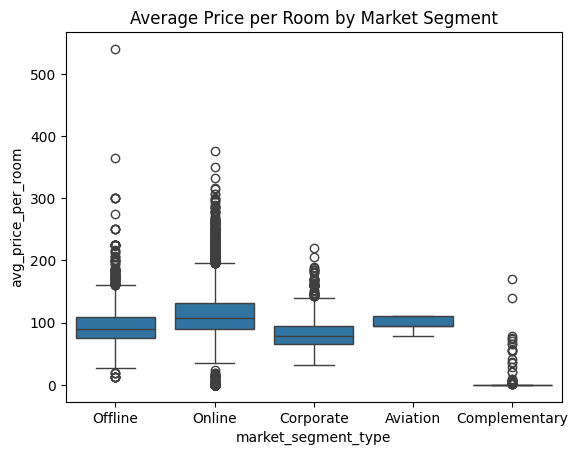

In [43]:
sns.boxplot(data=df, x='market_segment_type', y='avg_price_per_room')
plt.title('Average Price per Room by Market Segment');

### 4. What percentage of bookings are canceled?

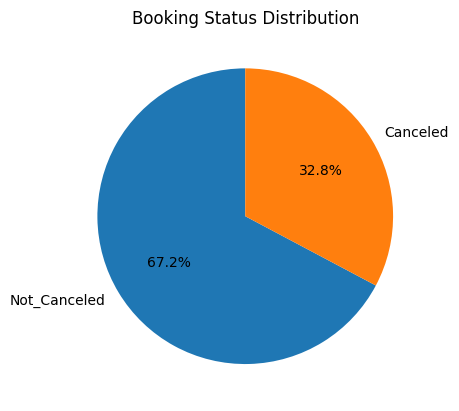

In [44]:
ptg = df['booking_status'].value_counts()
ptg.plot(kind = 'pie', autopct = '%1.1f%%', startangle = 90)

plt.title('Booking Status Distribution')
plt.ylabel('');

### 5. Repeating guests are guests who stay in the hotel often and are important to brand equity. What percentage of repeating guests cancel?

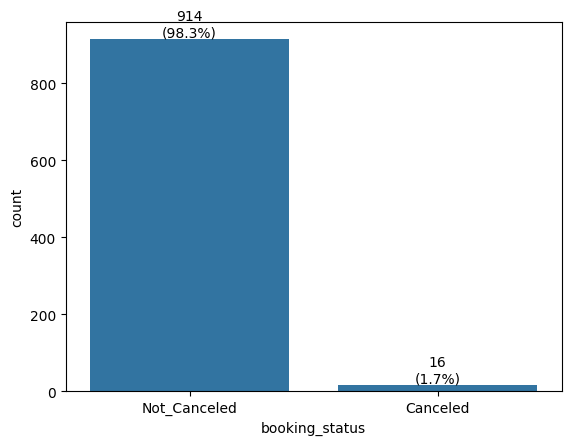

In [45]:
repeated_guests_df = df[df['repeated_guest'] == 1]
ax = sns.countplot(data = repeated_guests_df, x = 'booking_status')

total = len(repeated_guests_df)
for container in ax.containers:
  labels = [f'{v.get_height():.0f}\n({v.get_height()/total*100:.1f}%)' for v in container]
  ax.bar_label(container, labels = labels)

### 6. Many guests have special requirements when booking a hotel room. Do these requirements affect booking cancellation?

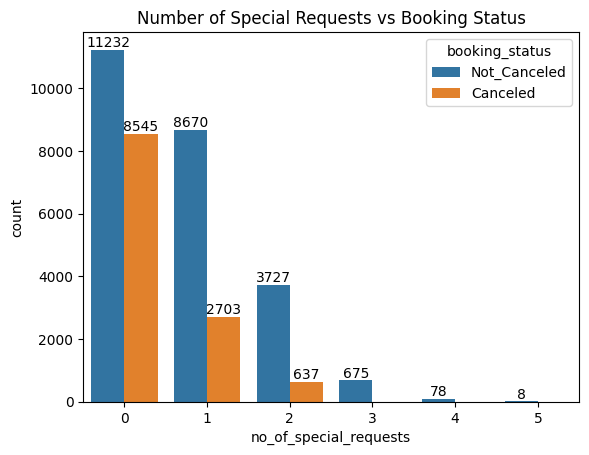

In [46]:
ax = sns.countplot(data = df, x = 'no_of_special_requests', hue = 'booking_status')
for container in ax.containers:
    ax.bar_label(container)
plt.title('Number of Special Requests vs Booking Status');

# Outlier Detection

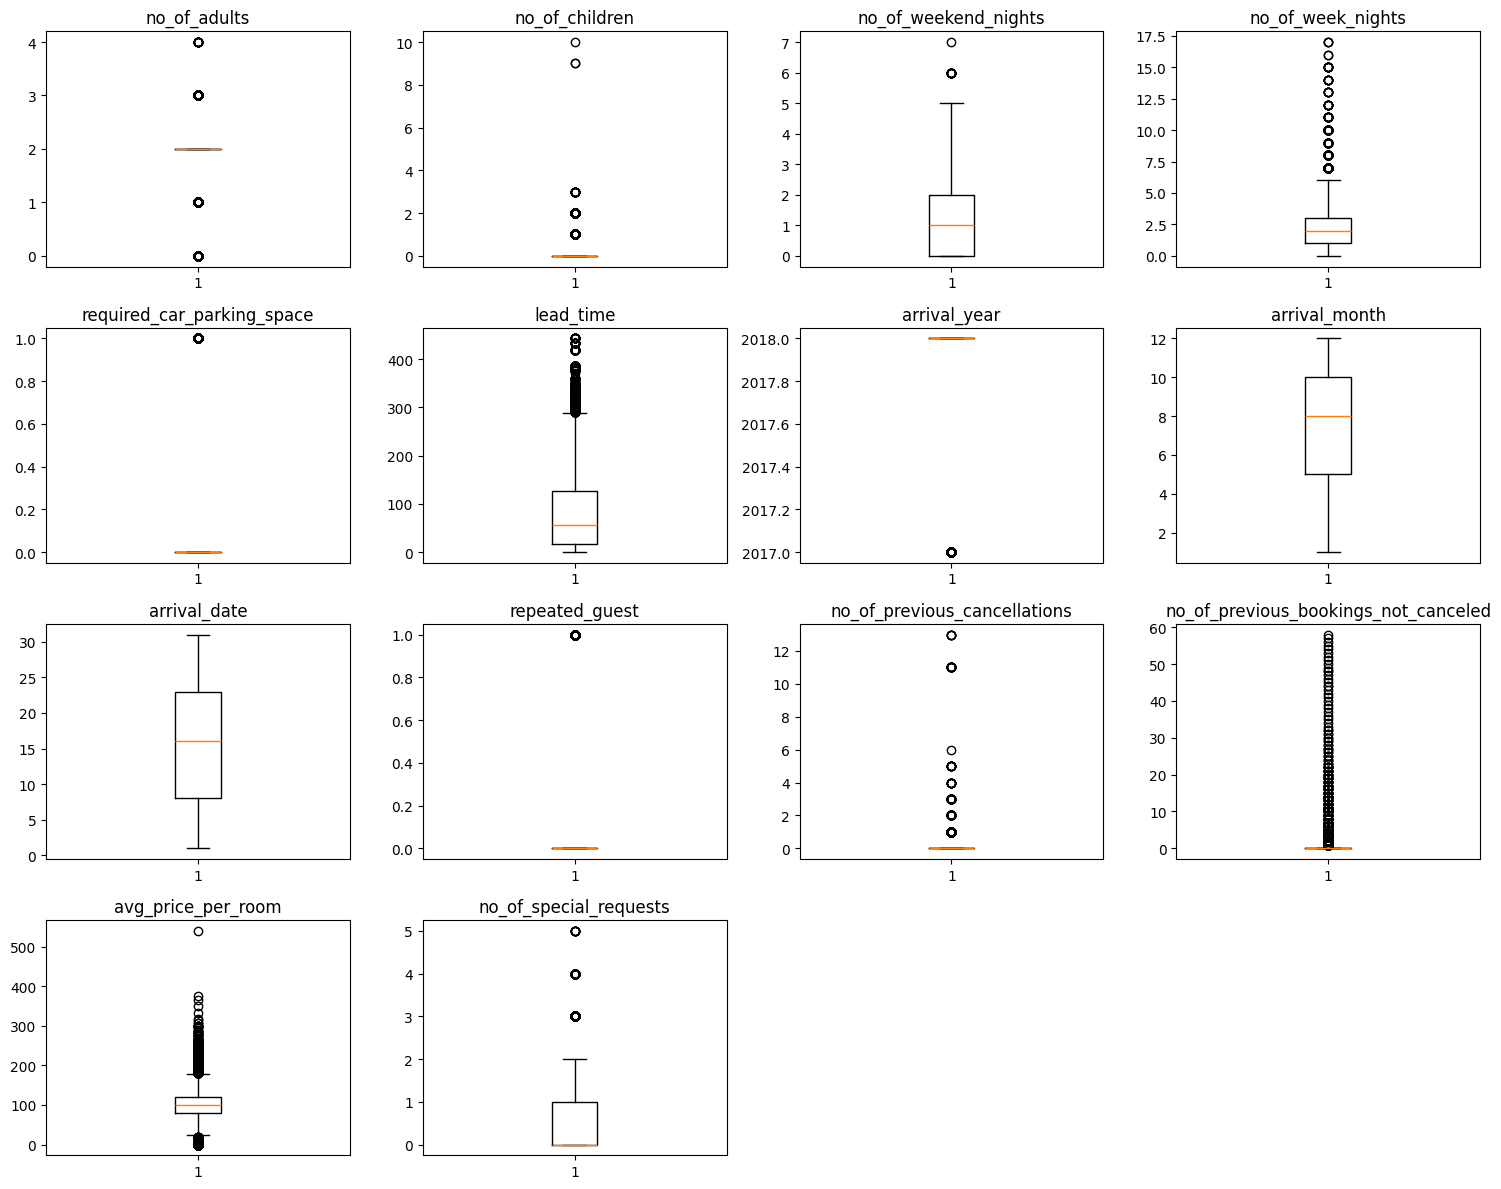

In [47]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()

plt.figure(figsize=(15, 12))

for i, variable in enumerate(numeric_columns):
    plt.subplot(4, 4, i + 1)
    plt.boxplot(df[variable], whis=1.5)
    plt.tight_layout()
    plt.title(variable)

# Modeling

## Data Preparation

In [48]:
df['type_of_meal_plan'].value_counts()

,count
type_of_meal_plan,
Meal Plan 1,27835
Not Selected,5130
Meal Plan 2,3305
Meal Plan 3,5


In [49]:
df['room_type_reserved'].value_counts()

,count
room_type_reserved,
Room_Type 1,28130
Room_Type 4,6057
Room_Type 6,966
Room_Type 2,692
Room_Type 5,265
Room_Type 7,158
Room_Type 3,7


In [50]:
df['market_segment_type'].value_counts()

,count
market_segment_type,
Online,23214
Offline,10528
Corporate,2017
Complementary,391
Aviation,125


In [51]:
for feature in df.columns:
  if df[feature].dtype == 'object':
    df[feature] == pd.Categorical(df[feature])

In [52]:
replace_values = {
    'type_of_meal_plan': {'Not Selected':-1, 'Meal Plan 1': 1, 'Meal Plan 2': 2, 'Meal Plan 3': 3},
    'room_type_reserved': {'Room_Type 1': 1, 'Room_Type 2': 2, 'Room_Type 3': 3, 'Room_Type 4': 4, 'Room_Type 5': 5, 'Room_Type 6': 6, 'Room_Type 7': 7},
    'market_segment_type': {'Online': 1, 'Offline': 2, 'Corporate': 3, 'Complementary': 4, 'Aviation': 5},
    'booking_status': {'Canceled': 0, 'Not_Canceled': 1}
}

In [53]:
df = df.replace(replace_values)
df.head()

,Booking_ID,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,INN00001,2,0,1,2,1,0,1,224,2017,10,2,2,0,0,0,65.00000,0,1
1,INN00002,2,0,2,3,-1,0,1,5,2018,11,6,1,0,0,0,106.68000,1,1
2,INN00003,1,0,2,1,1,0,1,1,2018,2,28,1,0,0,0,60.00000,0,0
3,INN00004,2,0,0,2,1,0,1,211,2018,5,20,1,0,0,0,100.00000,0,0
4,INN00005,2,0,1,1,-1,0,1,48,2018,4,11,1,0,0,0,94.50000,0,0


In [54]:
df = df.drop('Booking_ID',axis = 1)

In [55]:
X = df.drop('booking_status', axis = 1)
y = df.pop('booking_status')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.30, random_state = 1)

## Logistic Regression

In [56]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [57]:
logit = sm.Logit(y_train, X_train.astype(float))
lg = logit.fit()
print(lg.summary())

Optimization terminated successfully.
         Current function value: 0.439154
         Iterations 11
                           Logit Regression Results                           
Dep. Variable:         booking_status   No. Observations:                25392
Model:                          Logit   Df Residuals:                    25375
Method:                           MLE   Df Model:                           16
Date:                Sun, 11 Oct 2026   Pseudo R-squ.:                  0.3070
Time:                        10:49:35   Log-Likelihood:                -11151.
converged:                       True   LL-Null:                       -16091.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                           coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------
no_of_adults                            -0.0460      0.

In [58]:
pred_train = lg.predict(X_train) > 0.5
pred_train = np.round(pred_train)

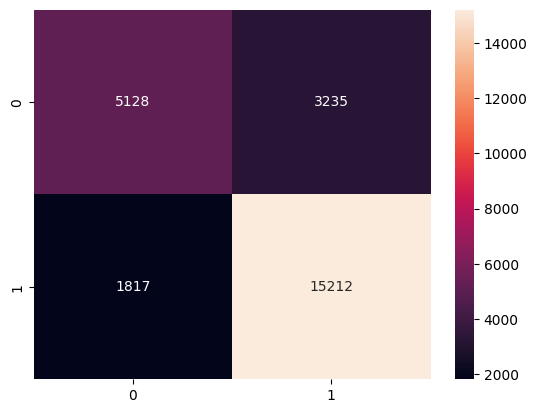

In [59]:
cm = confusion_matrix(y_train, pred_train)
sns.heatmap(cm, annot = True, fmt = 'g');

In [60]:
vif_series = pd.Series(
    [variance_inflation_factor(X_train.values, i) for i in range(X_train.shape[1])],
    index=X_train.columns,
    dtype=float,
)
print("Series before feature selection: \n\n{}\n".format(vif_series))

Series before feature selection: 

no_of_adults                           1.29871
no_of_children                         1.25778
no_of_weekend_nights                   1.06311
no_of_week_nights                      1.08329
type_of_meal_plan                      1.31880
required_car_parking_space             1.03423
room_type_reserved                     1.50285
lead_time                              1.27943
arrival_year                           1.37034
arrival_month                          1.26746
arrival_date                           1.00505
market_segment_type                    1.64326
repeated_guest                         1.66674
no_of_previous_cancellations           1.38627
no_of_previous_bookings_not_canceled   1.64236
avg_price_per_room                     1.74485
no_of_special_requests                 1.19157
dtype: float64



In [61]:
print(lg.summary())

                           Logit Regression Results                           
Dep. Variable:         booking_status   No. Observations:                25392
Model:                          Logit   Df Residuals:                    25375
Method:                           MLE   Df Model:                           16
Date:                Sun, 11 Oct 2026   Pseudo R-squ.:                  0.3070
Time:                        10:49:39   Log-Likelihood:                -11151.
converged:                       True   LL-Null:                       -16091.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                           coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------
no_of_adults                            -0.0460      0.036     -1.265      0.206      -0.117       0.025
no_of_children                           0.0039      

In [62]:
cols = X_train.columns.tolist()

max_p_value = 1

while len(cols) > 0:
    X_train_aux = X_train[cols]

    model = sm.Logit(y_train, X_train_aux).fit(disp=False)

    p_values = model.pvalues
    max_p_value = max(p_values)

    feature_with_p_max = p_values.idxmax()

    if max_p_value > 0.05:
        cols.remove(feature_with_p_max)
    else:
        break

selected_features = cols
print(selected_features)

['no_of_weekend_nights', 'no_of_week_nights', 'type_of_meal_plan', 'required_car_parking_space', 'room_type_reserved', 'lead_time', 'arrival_year', 'arrival_month', 'market_segment_type', 'repeated_guest', 'avg_price_per_room', 'no_of_special_requests']


In [63]:
X_train2 = X_train[selected_features]

In [64]:
logit2 = sm.Logit(y_train, X_train2.astype(float))
lg2 = logit2.fit()
print(lg2.summary())

Optimization terminated successfully.
         Current function value: 0.439301
         Iterations 9
                           Logit Regression Results                           
Dep. Variable:         booking_status   No. Observations:                25392
Model:                          Logit   Df Residuals:                    25380
Method:                           MLE   Df Model:                           11
Date:                Sun, 11 Oct 2026   Pseudo R-squ.:                  0.3068
Time:                        10:49:40   Log-Likelihood:                -11155.
converged:                       True   LL-Null:                       -16091.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------
no_of_weekend_nights          -0.1163      0.019     -6.012      0.000      

In [65]:
odds = np.exp(lg2.params)

perc_change_odds = (np.exp(lg2.params) - 1) * 100

pd.set_option("display.max_columns", None)
pd.DataFrame({"Odds": odds, "Change_odd%": perc_change_odds}, index=X_train2.columns).T

,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,market_segment_type,repeated_guest,avg_price_per_room,no_of_special_requests
Odds,0.89022,0.94941,1.23645,4.53602,1.09066,0.98532,1.00069,1.06692,3.22807,3.58168,0.97963,3.78556
Change_odd%,-10.97822,-5.05863,23.64493,353.60214,9.06596,-1.46817,0.06852,6.69158,222.80749,258.16763,-2.03732,278.55591


In [66]:
pred_train2 = lg2.predict(X_train2) > 0.5
pred_train2 = np.round(pred_train2)

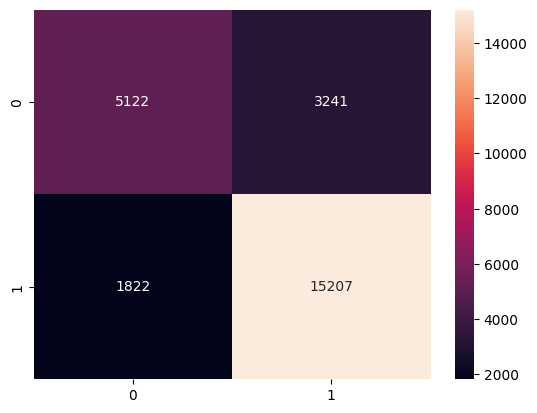

In [67]:
cm = confusion_matrix(y_train, pred_train2)
sns.heatmap(cm, annot = True, fmt = 'g');

In [68]:
print('Logistic Regression Training Accuracy:', lg2.prsquared)

Logistic Regression Training Accuracy: 0.306791019718039


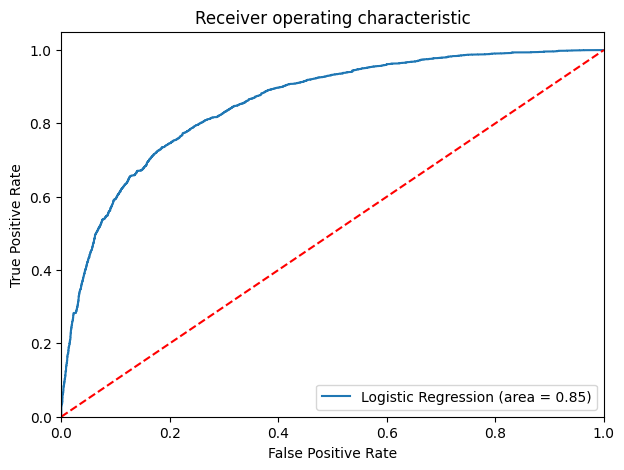

In [69]:
logit_roc_auc_train = roc_auc_score(y_train, lg2.predict(X_train2))
fpr, tpr, thresholds = roc_curve(y_train, lg2.predict(X_train2))
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label="Logistic Regression (area = %0.2f)" % logit_roc_auc_train)
plt.plot([0, 1], [0, 1], "r--")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver operating characteristic")
plt.legend(loc="lower right")
plt.show()

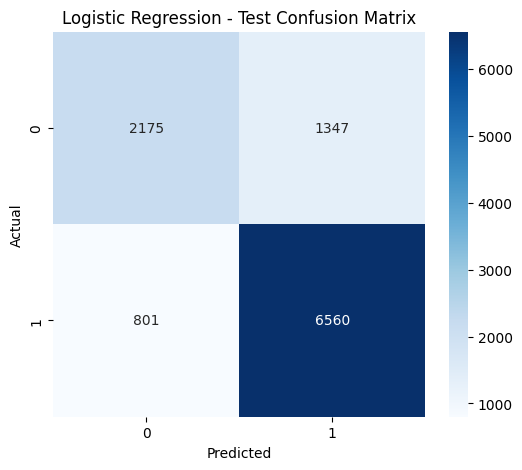

In [70]:
X_test2 = X_test[selected_features]

pred_test2 = lg2.predict(X_test2) > 0.5
pred_test2 = np.round(pred_test2)

cm_test = confusion_matrix(y_test, pred_test2)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_test, annot=True, fmt='g', cmap='Blues')
plt.title('Logistic Regression - Test Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [71]:
print('Logistic Regression Test Accuracy Score:', accuracy_score(y_test, pred_test2))

Logistic Regression Test Accuracy Score: 0.8026279518515115


## Decision Tree

### Decision Tree

In [72]:
dTree = DecisionTreeClassifier(criterion = 'gini', random_state = 1)
dTree.fit(X_train, y_train)

DecisionTreeClassifier(random_state=1)

In [73]:
print('Decision Tree Training Accuracy:', dTree.score(X_train, y_train))
print('Decision Tree Testing Accuracy:', dTree.score(X_test, y_test))

Decision Tree Training Accuracy: 0.994210775047259
Decision Tree Testing Accuracy: 0.8697050445649177


In [74]:
def make_confusion_matrix(model, y_actual, labels = [1,0]):
    y_predict = model.predict(X_test)
    cm = confusion_matrix(y_actual, y_predict, labels = [0,1])

    df_cm = pd.DataFrame(cm, index = [i for i in ['Actual-No', 'Actual-Yes']], columns = [i for i in ['Actual-No', 'Actual-Yes']])

    group_cnts = ['{0:0.0f}'.format(value) for value in cm.flatten()]
    group_percentages = ['{0:.2%}'.format(value) for value in cm.flatten()/np.sum(cm)]

    labels = [f'{v1}\n{v2}' for v1, v2 in zip(group_cnts, group_percentages)]
    labels = np.asarray(labels).reshape(2,2)

    plt.figure(figsize = (8,5))
    sns.heatmap(df_cm, annot = labels, fmt = '', cmap = 'Blues')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix');

In [75]:
def get_recall_score(model):
    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)
    print('Recall on training set:', recall_score(y_train, pred_train))
    print('Recall on test set:', recall_score(y_test, pred_test))

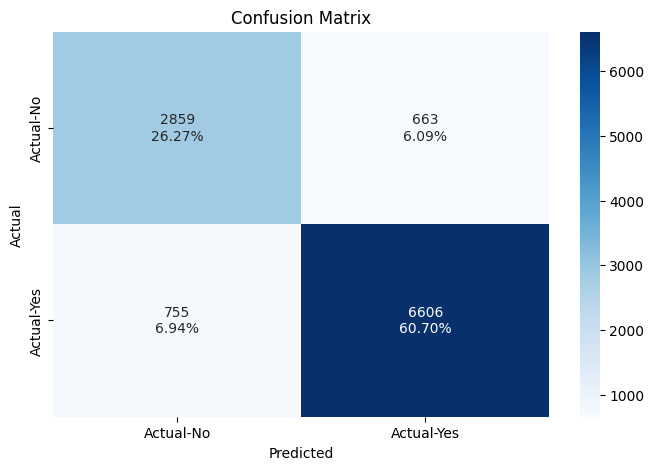

In [76]:
make_confusion_matrix(dTree, y_test)

In [77]:
get_recall_score(dTree)

Recall on training set: 0.9957719184919842
Recall on test set: 0.8974324140741747


In [78]:
feature_names = list(X.columns)
print(feature_names)

['no_of_adults', 'no_of_children', 'no_of_weekend_nights', 'no_of_week_nights', 'type_of_meal_plan', 'required_car_parking_space', 'room_type_reserved', 'lead_time', 'arrival_year', 'arrival_month', 'arrival_date', 'market_segment_type', 'repeated_guest', 'no_of_previous_cancellations', 'no_of_previous_bookings_not_canceled', 'avg_price_per_room', 'no_of_special_requests']


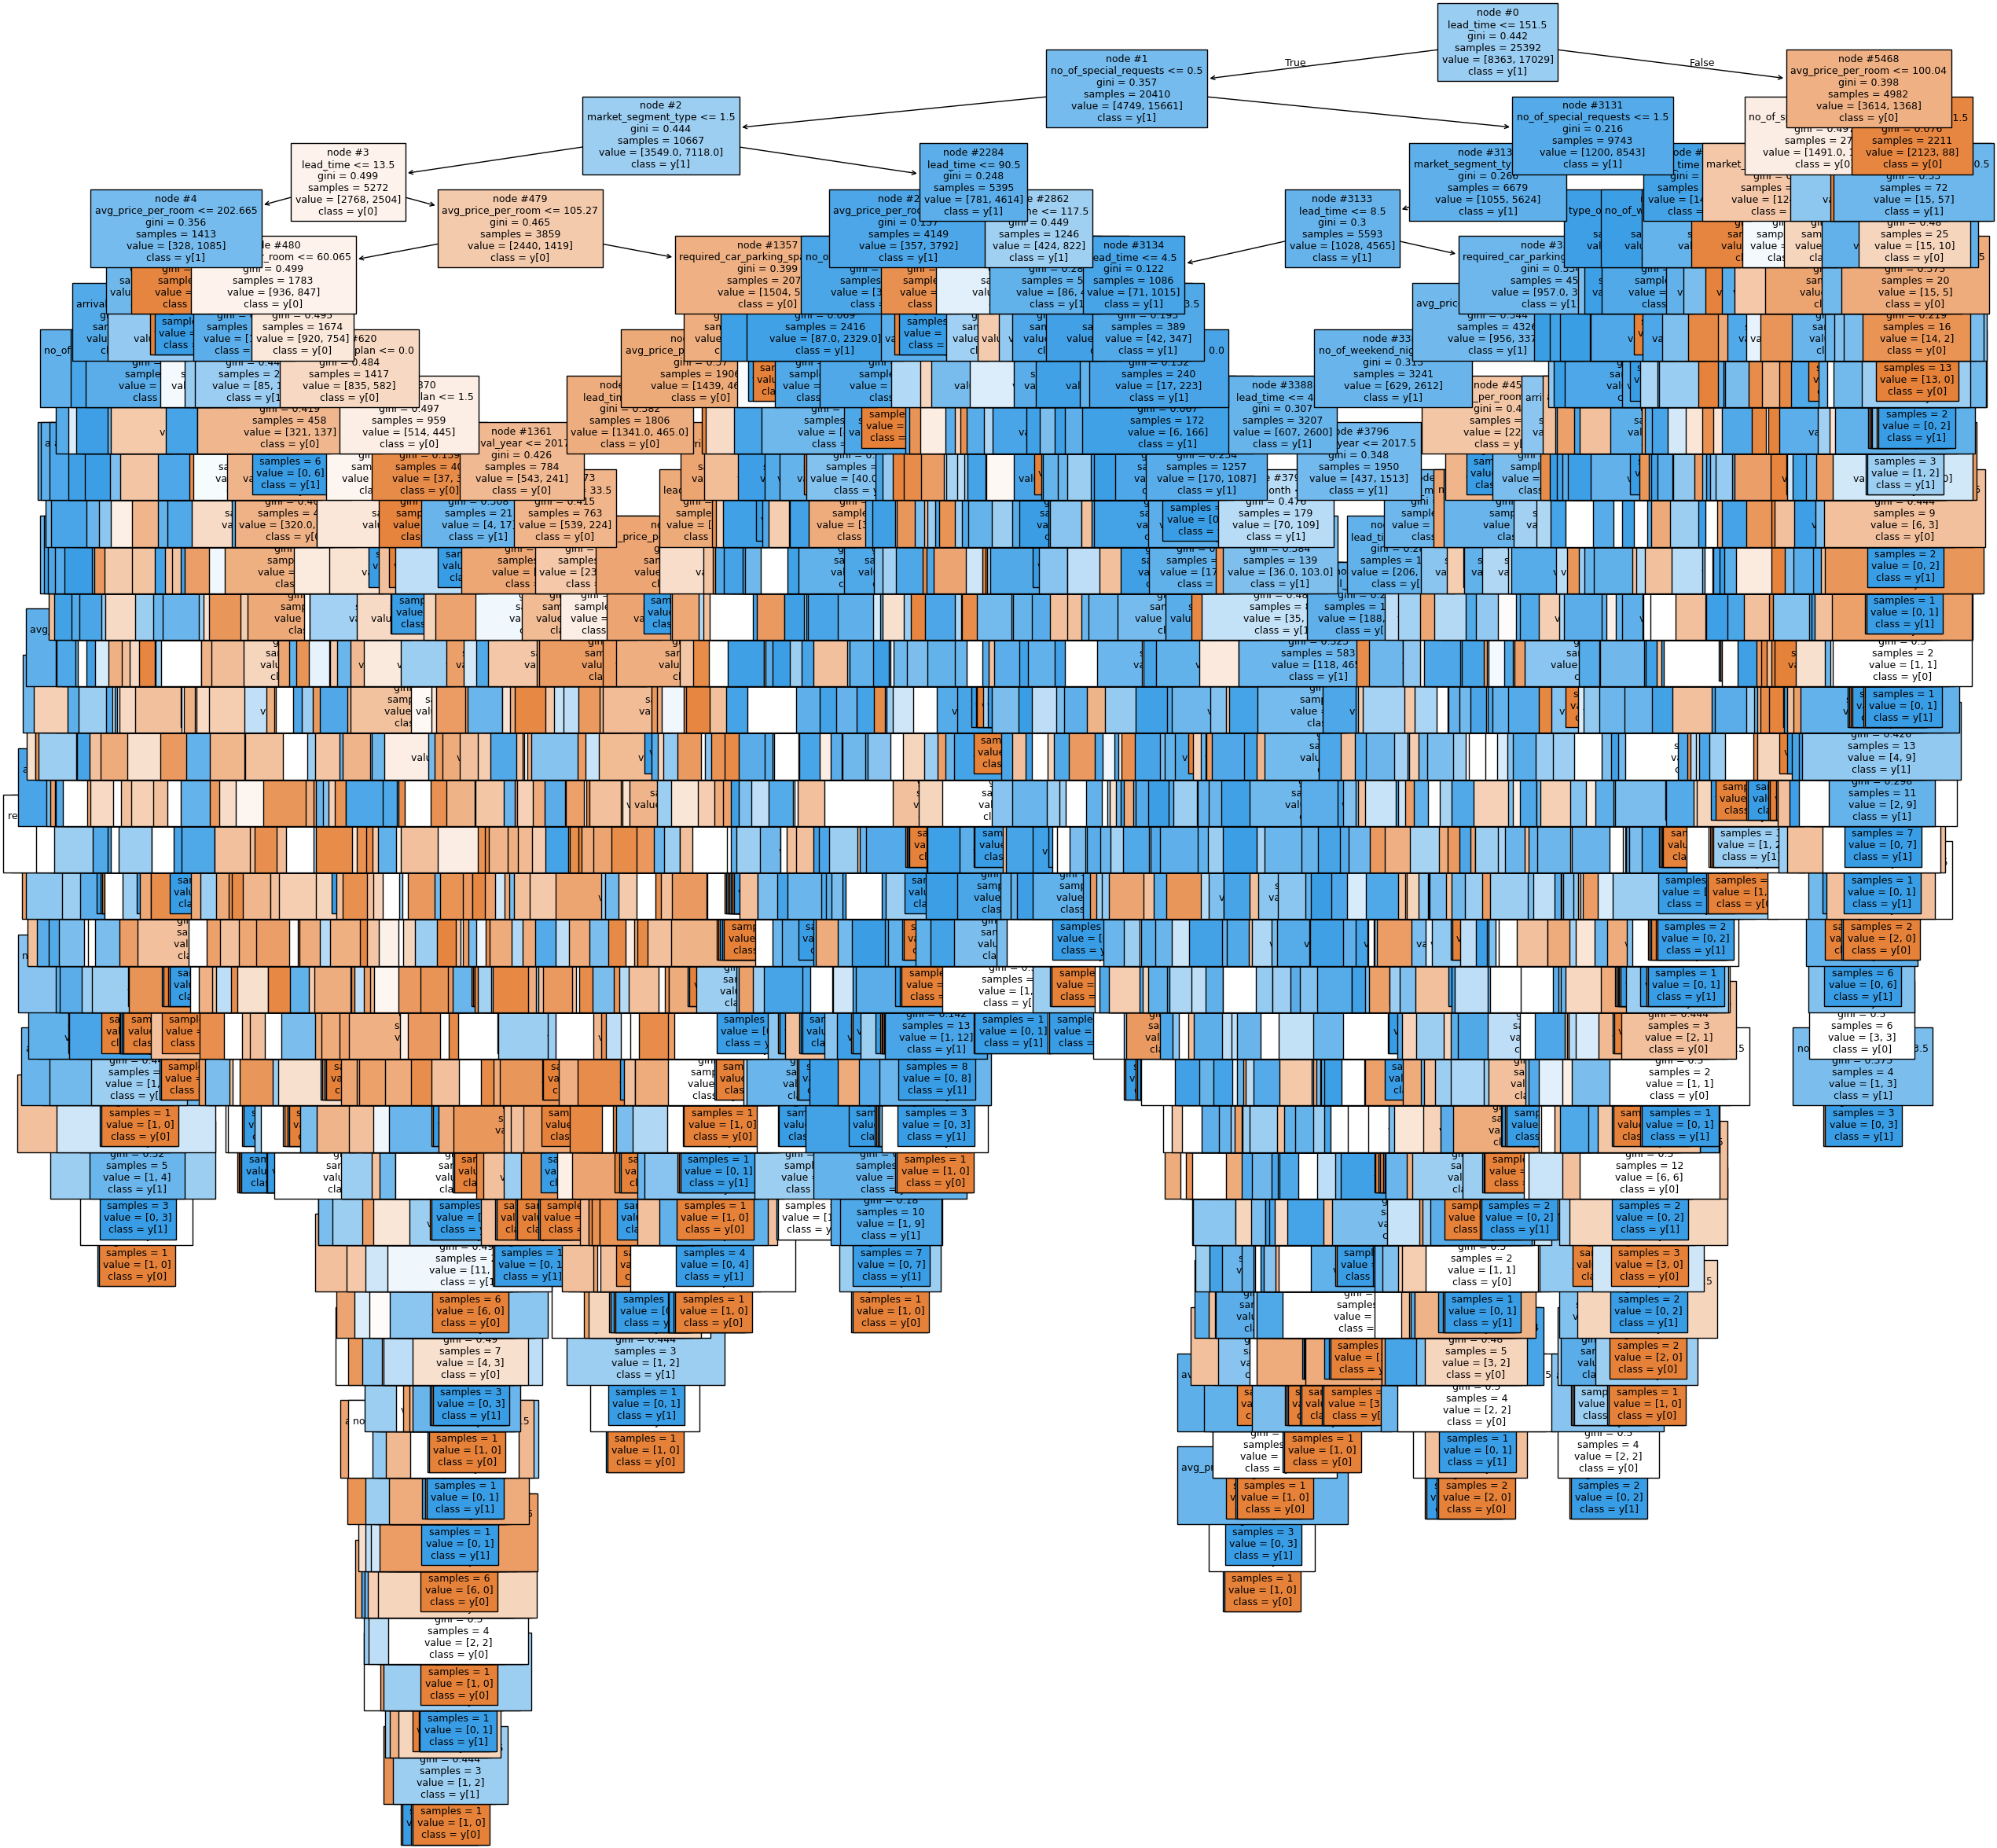

In [79]:
plt.figure(figsize = (30,30))
tree.plot_tree(dTree, feature_names = feature_names, filled = True, fontsize = 9, node_ids = True, class_names = True);

In [80]:
print(tree.export_text(dTree, feature_names = feature_names, show_weights = True))

|--- lead_time <= 151.50
|   |--- no_of_special_requests <= 0.50
|   |   |--- market_segment_type <= 1.50
|   |   |   |--- lead_time <= 13.50
|   |   |   |   |--- avg_price_per_room <= 202.67
|   |   |   |   |   |--- lead_time <= 3.50
|   |   |   |   |   |   |--- arrival_month <= 5.50
|   |   |   |   |   |   |   |--- no_of_weekend_nights <= 1.50
|   |   |   |   |   |   |   |   |--- arrival_month <= 1.50
|   |   |   |   |   |   |   |   |   |--- weights: [0.00, 56.00] class: 1
|   |   |   |   |   |   |   |   |--- arrival_month >  1.50
|   |   |   |   |   |   |   |   |   |--- avg_price_per_room <= 77.50
|   |   |   |   |   |   |   |   |   |   |--- weights: [0.00, 24.00] class: 1
|   |   |   |   |   |   |   |   |   |--- avg_price_per_room >  77.50
|   |   |   |   |   |   |   |   |   |   |--- arrival_date <= 26.50
|   |   |   |   |   |   |   |   |   |   |   |--- truncated branch of depth 14
|   |   |   |   |   |   |   |   |   |   |--- arrival_date >  26.50
|   |   |   |   |   |   |   |   | 

In [81]:
print(pd.DataFrame(dTree.feature_importances_, columns = ['Imp'], index = X_train.columns).sort_values(by = 'Imp', ascending = False))

                                         Imp
lead_time                            0.35137
avg_price_per_room                   0.17440
market_segment_type                  0.09713
arrival_date                         0.08947
no_of_special_requests               0.06767
arrival_month                        0.06505
no_of_week_nights                    0.04290
no_of_weekend_nights                 0.03916
no_of_adults                         0.02623
arrival_year                         0.01180
type_of_meal_plan                    0.01145
room_type_reserved                   0.01113
required_car_parking_space           0.00708
no_of_children                       0.00426
repeated_guest                       0.00059
no_of_previous_bookings_not_canceled 0.00030
no_of_previous_cancellations         0.00000


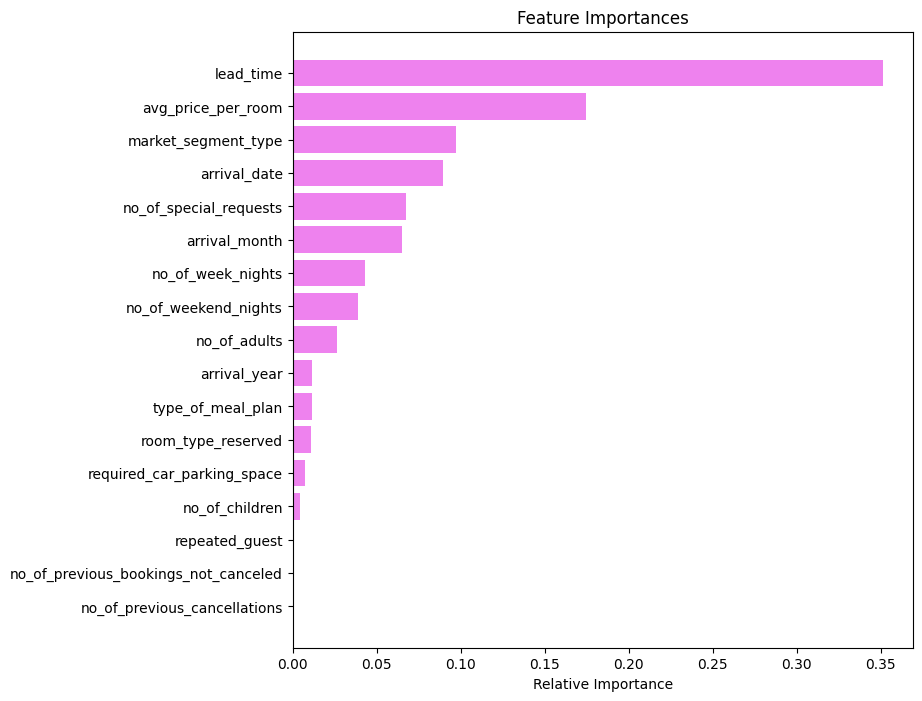

In [82]:
importances = dTree.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(8, 8))
plt.title("Feature Importances")
plt.barh(range(len(indices)), importances[indices], color="violet", align="center")
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Relative Importance")
plt.show()

### Decision Tree keeping depth as 3

In [83]:
dTree1 = DecisionTreeClassifier(criterion = 'gini', max_depth = 3, random_state = 1)
dTree1.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=3, random_state=1)

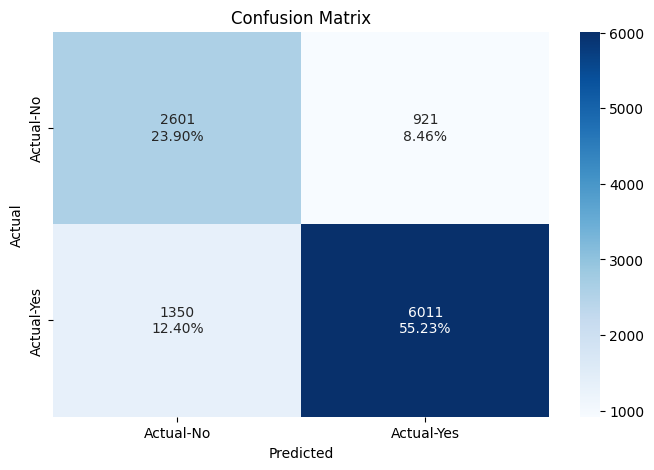

In [84]:
make_confusion_matrix(dTree1, y_test)

In [85]:
print('Decision Tree Training Accuracy:', dTree1.score(X_train, y_train))
print('Decision Tree Testing Accuracy:', dTree1.score(X_test, y_test))

Decision Tree Training Accuracy: 0.7844202898550725
Decision Tree Testing Accuracy: 0.7913259211614444


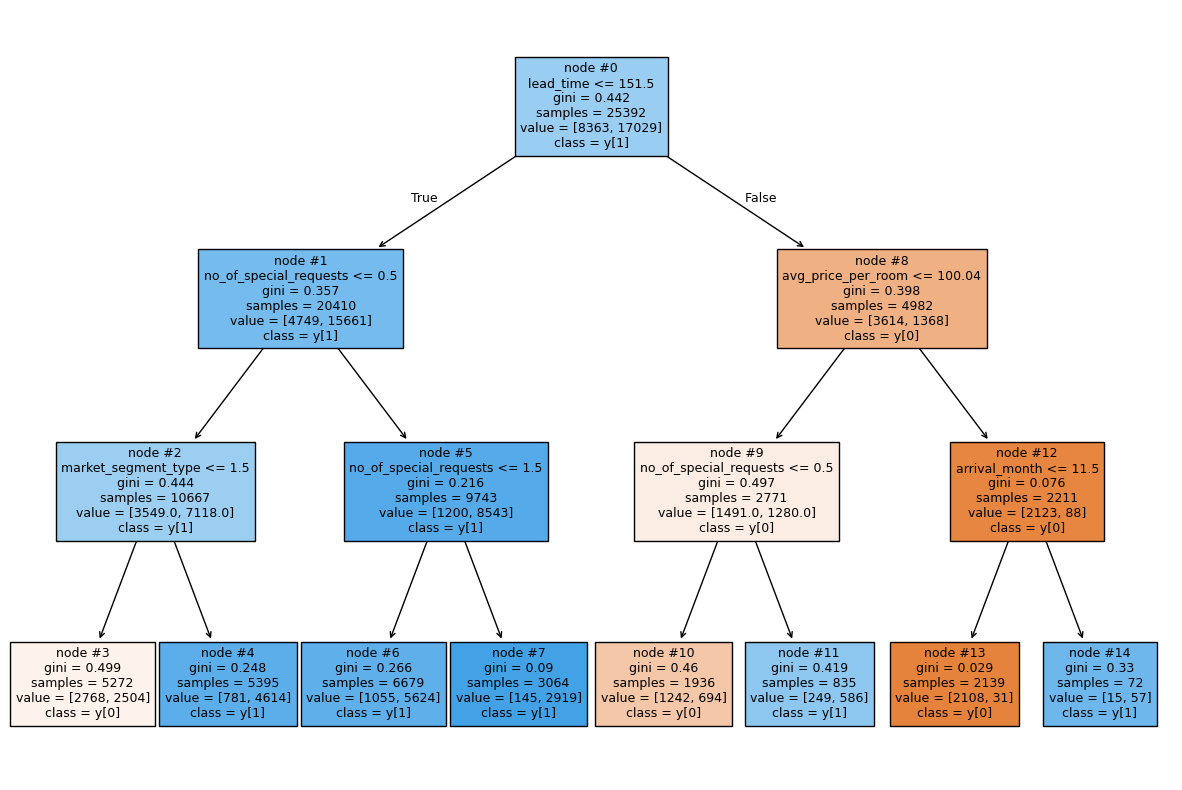

In [86]:
plt.figure(figsize = (15,10))
tree.plot_tree(dTree1, feature_names = feature_names, filled = True, fontsize = 9, node_ids = True, class_names = True);

In [87]:
print(tree.export_text(dTree1, feature_names = feature_names, show_weights = True))

|--- lead_time <= 151.50
|   |--- no_of_special_requests <= 0.50
|   |   |--- market_segment_type <= 1.50
|   |   |   |--- weights: [2768.00, 2504.00] class: 0
|   |   |--- market_segment_type >  1.50
|   |   |   |--- weights: [781.00, 4614.00] class: 1
|   |--- no_of_special_requests >  0.50
|   |   |--- no_of_special_requests <= 1.50
|   |   |   |--- weights: [1055.00, 5624.00] class: 1
|   |   |--- no_of_special_requests >  1.50
|   |   |   |--- weights: [145.00, 2919.00] class: 1
|--- lead_time >  151.50
|   |--- avg_price_per_room <= 100.04
|   |   |--- no_of_special_requests <= 0.50
|   |   |   |--- weights: [1242.00, 694.00] class: 0
|   |   |--- no_of_special_requests >  0.50
|   |   |   |--- weights: [249.00, 586.00] class: 1
|   |--- avg_price_per_room >  100.04
|   |   |--- arrival_month <= 11.50
|   |   |   |--- weights: [2108.00, 31.00] class: 0
|   |   |--- arrival_month >  11.50
|   |   |   |--- weights: [15.00, 57.00] class: 1



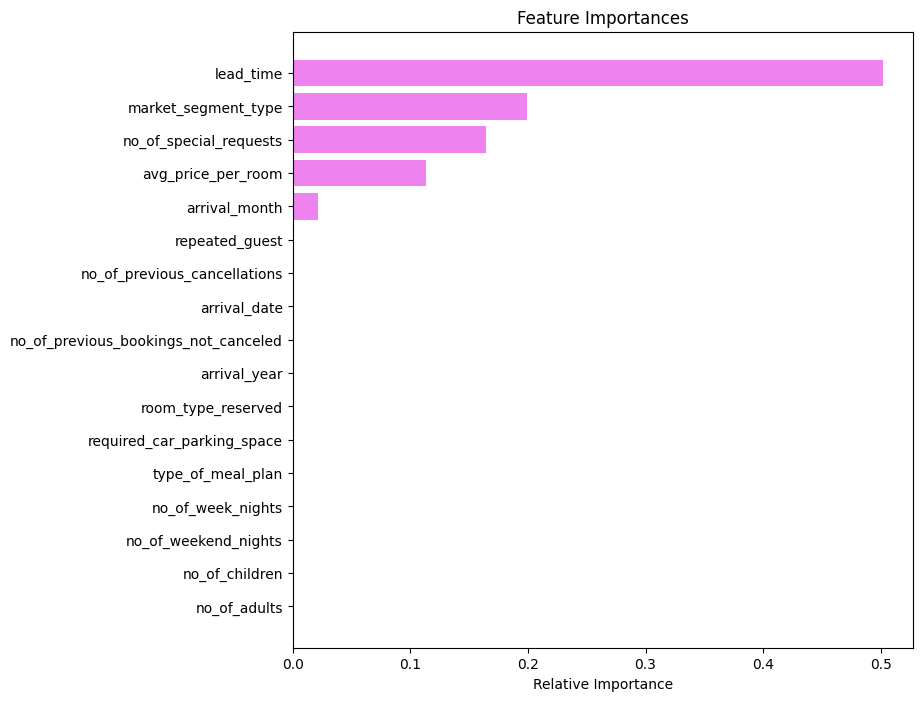

In [88]:
importances = dTree1.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(8, 8))
plt.title("Feature Importances")
plt.barh(range(len(indices)), importances[indices], color="violet", align="center")
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Relative Importance")
plt.show()

### GridSearch for Hyperparameter Tuning

In [89]:
from sklearn import metrics

estimator = DecisionTreeClassifier(random_state=1)
parameters = {
    'max_depth': np.arange(1, 10),
    'min_samples_leaf': [1, 2, 5, 7, 10, 15, 20],
    'max_leaf_nodes': [2, 3, 5, 10],
    'min_impurity_decrease': [0.001, 0.01, 0.1]
}

acc_scorer = metrics.make_scorer(metrics.accuracy_score)
grid_obj = GridSearchCV(estimator, parameters, scoring=acc_scorer)
grid_obj = grid_obj.fit(X_train, y_train)

clf = grid_obj.best_estimator_
clf.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=np.int64(5), max_leaf_nodes=10,
                       min_impurity_decrease=0.001, random_state=1)

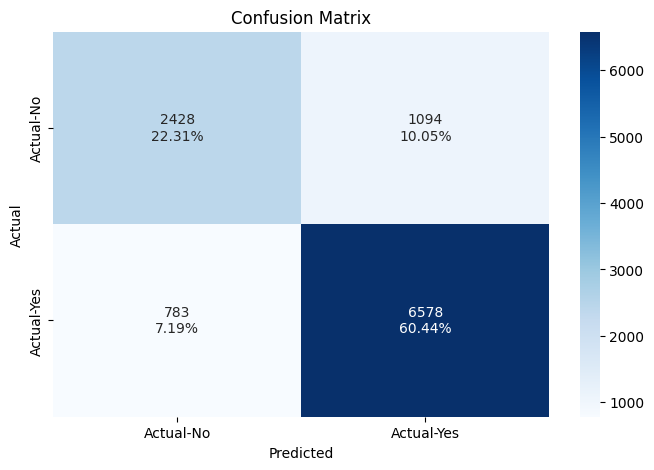

In [90]:
make_confusion_matrix(clf, y_test)

In [91]:
print('Decision Tree Training Accuracy:', clf.score(X_train, y_train))
print('Decision Tree Testing Accuracy:', clf.score(X_test, y_test))

Decision Tree Training Accuracy: 0.8241572148708255
Decision Tree Testing Accuracy: 0.8275291739410089


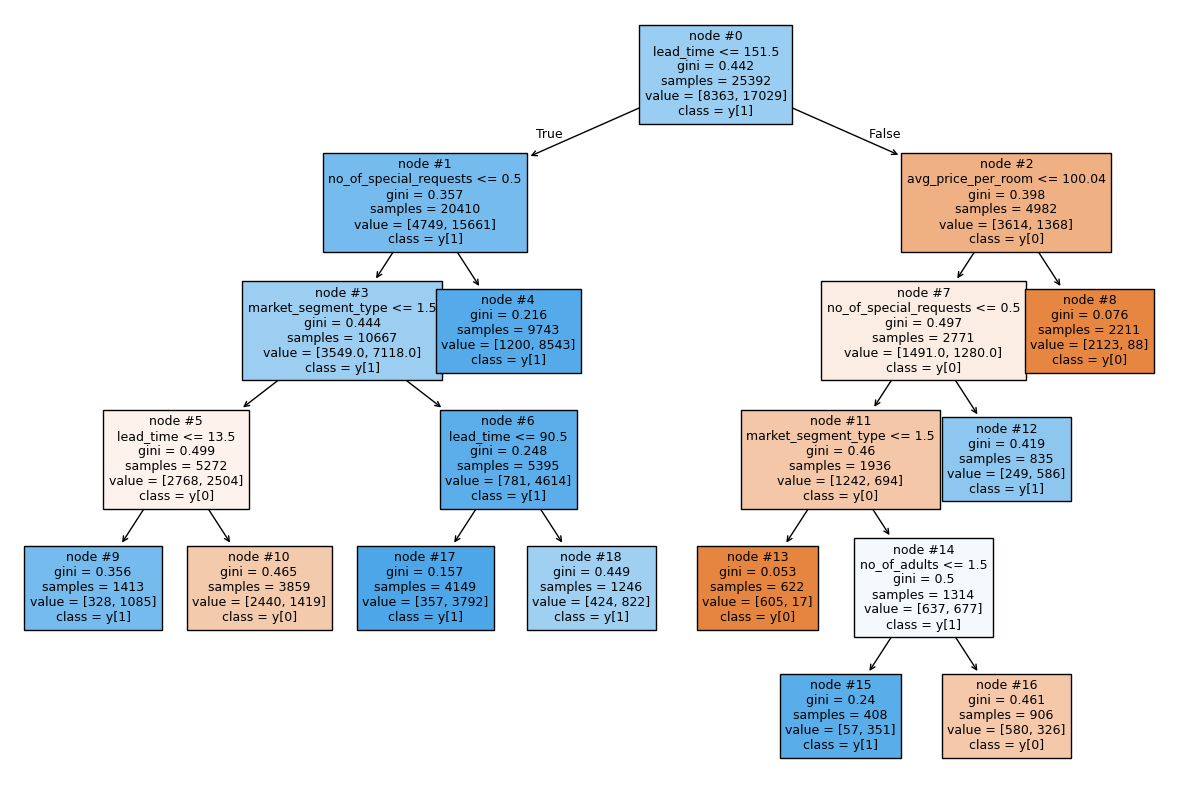

In [92]:
plt.figure(figsize = (15,10))
tree.plot_tree(clf, feature_names = feature_names, filled = True, fontsize = 9, node_ids = True, class_names = True);

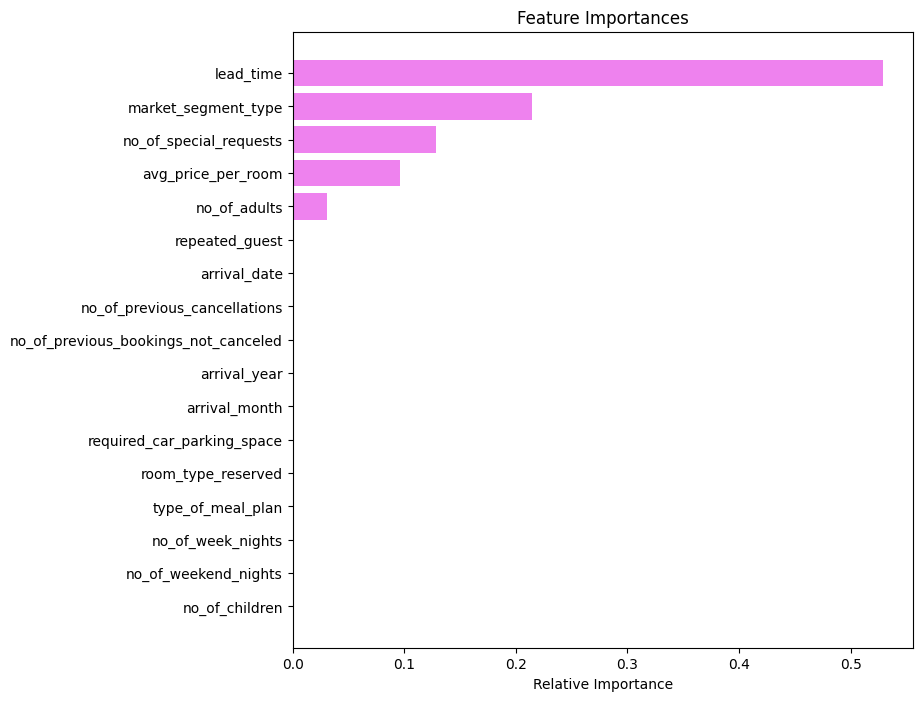

In [93]:
importances = clf.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(8, 8))
plt.title("Feature Importances")
plt.barh(range(len(indices)), importances[indices], color="violet", align="center")
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Relative Importance")
plt.show()

### Post Pruning

In [94]:
clf1 = DecisionTreeClassifier(random_state = 1)
path = clf1.cost_complexity_pruning_path(X_train,y_train)

ccp_alphas, impurities = path.ccp_alphas, path.impurities

In [95]:
pd.DataFrame(path)

,ccp_alphas,impurities
0,0.00000,0.00757
1,0.00000,0.00757
2,0.00000,0.00757
3,0.00000,0.00757
4,0.00000,0.00757
...,...,...
1337,0.00667,0.28690
1338,0.01304,0.29994
1339,0.01726,0.31720
1340,0.02399,0.36518


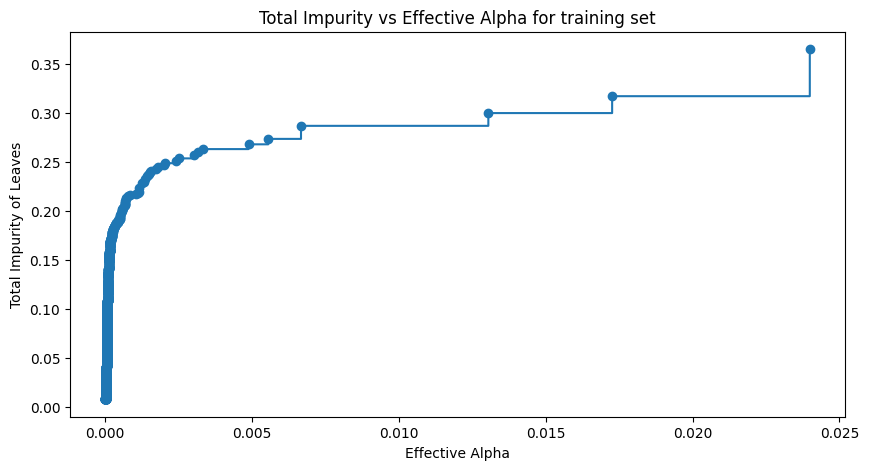

In [96]:
fig,ax = plt.subplots(figsize = (10,5))
ax.plot(ccp_alphas[:-1], impurities[:-1], marker = 'o', drawstyle = 'steps-post')
ax.set_xlabel('Effective Alpha')
ax.set_ylabel('Total Impurity of Leaves')
ax.set_title('Total Impurity vs Effective Alpha for training set');

In [97]:
clfs = []
for ccp_alpha in ccp_alphas:
    clf2 = DecisionTreeClassifier(random_state = 1, ccp_alpha = ccp_alpha)
    clf2.fit(X_train, y_train)
    clfs.append(clf2)
print('Number of nodes in the last tree: {} with ccp_alpha:{}'.format(clfs[-1].tree_.node_count, ccp_alphas[-1]))

Number of nodes in the last tree: 1 with ccp_alpha:0.07657789477371357


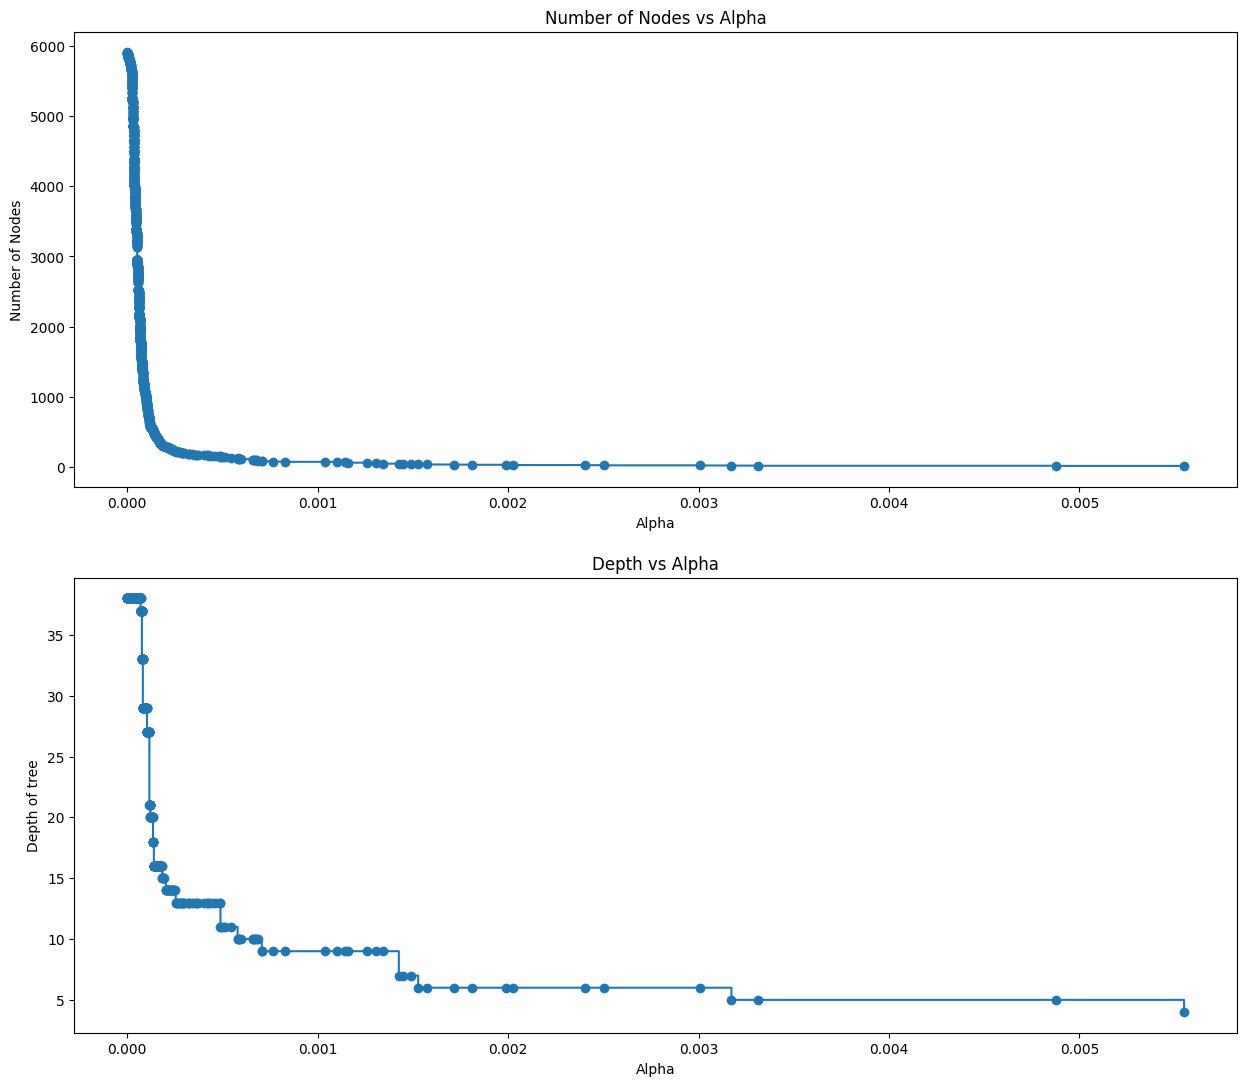

In [110]:
clfs = clfs[:-1]
ccp_alphas = ccp_alphas[:-1]

node_counts = [clf.tree_.node_count for clf in clfs]
depth = [clf.tree_.max_depth for clf in clfs]

fig,ax = plt.subplots(2,1, figsize = (15,13))
ax[0].plot(ccp_alphas, node_counts, marker = 'o', drawstyle = 'steps-post')
ax[0].set_xlabel('Alpha')
ax[0].set_ylabel('Number of Nodes')
ax[0].set_title('Number of Nodes vs Alpha')

ax[1].plot(ccp_alphas, depth, marker = 'o', drawstyle = 'steps-post')
ax[1].set_xlabel('Alpha')
ax[1].set_ylabel('Depth of tree')
ax[1].set_title('Depth vs Alpha');

In [99]:
train_scores = [clf.score(X_train, y_train) for clf in clfs]
test_scores = [clf.score(X_test, y_test) for clf in clfs]

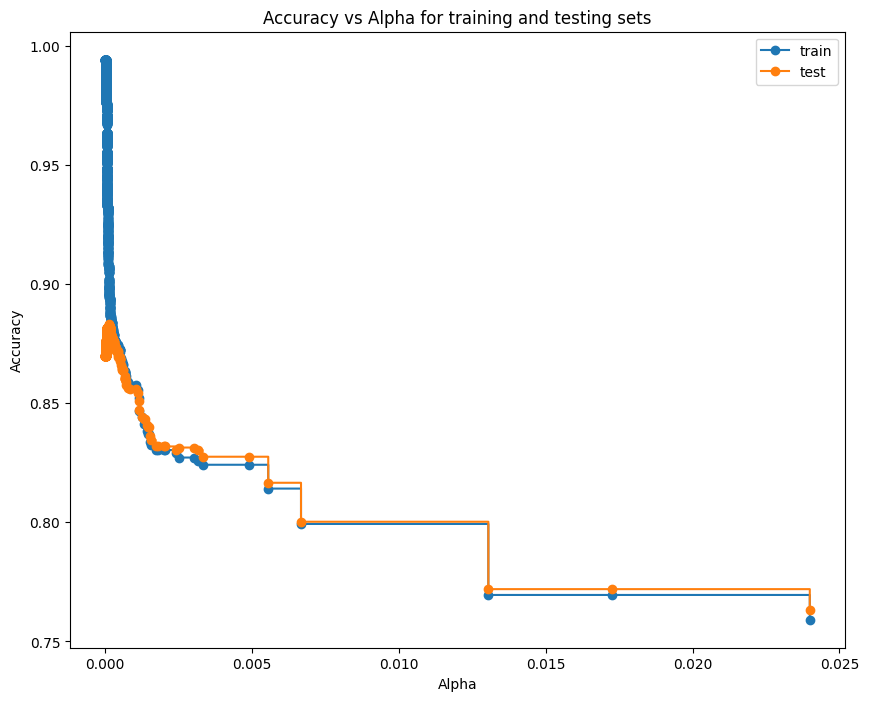

In [100]:
fig,ax = plt.subplots(figsize = (10,8))
ax.set_xlabel('Alpha')
ax.set_ylabel('Accuracy')
ax.set_title('Accuracy vs Alpha for training and testing sets')
ax.plot(ccp_alphas, train_scores, marker = 'o', label = 'train', drawstyle = 'steps-post')
ax.plot(ccp_alphas, test_scores, marker = 'o', label = 'test', drawstyle = 'steps-post')
ax.legend();

In [101]:
index_best_model = np.argmax(test_scores)
best_model = clfs[index_best_model]
print('Best model:', best_model)
print('Training accuracy:', train_scores[index_best_model])
print('Testing accuracy:', test_scores[index_best_model])

Best model: DecisionTreeClassifier(ccp_alpha=np.float64(0.00011799258961568554),
                       random_state=1)
Training accuracy: 0.9016225582860744
Testing accuracy: 0.883304235964348


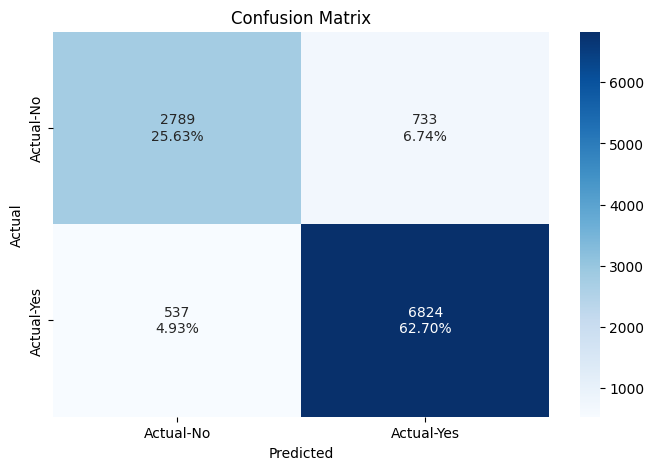

In [102]:
make_confusion_matrix(best_model, y_test)

In [103]:
get_recall_score(best_model)

Recall on training set: 0.9400434552821657
Recall on test set: 0.9270479554408368


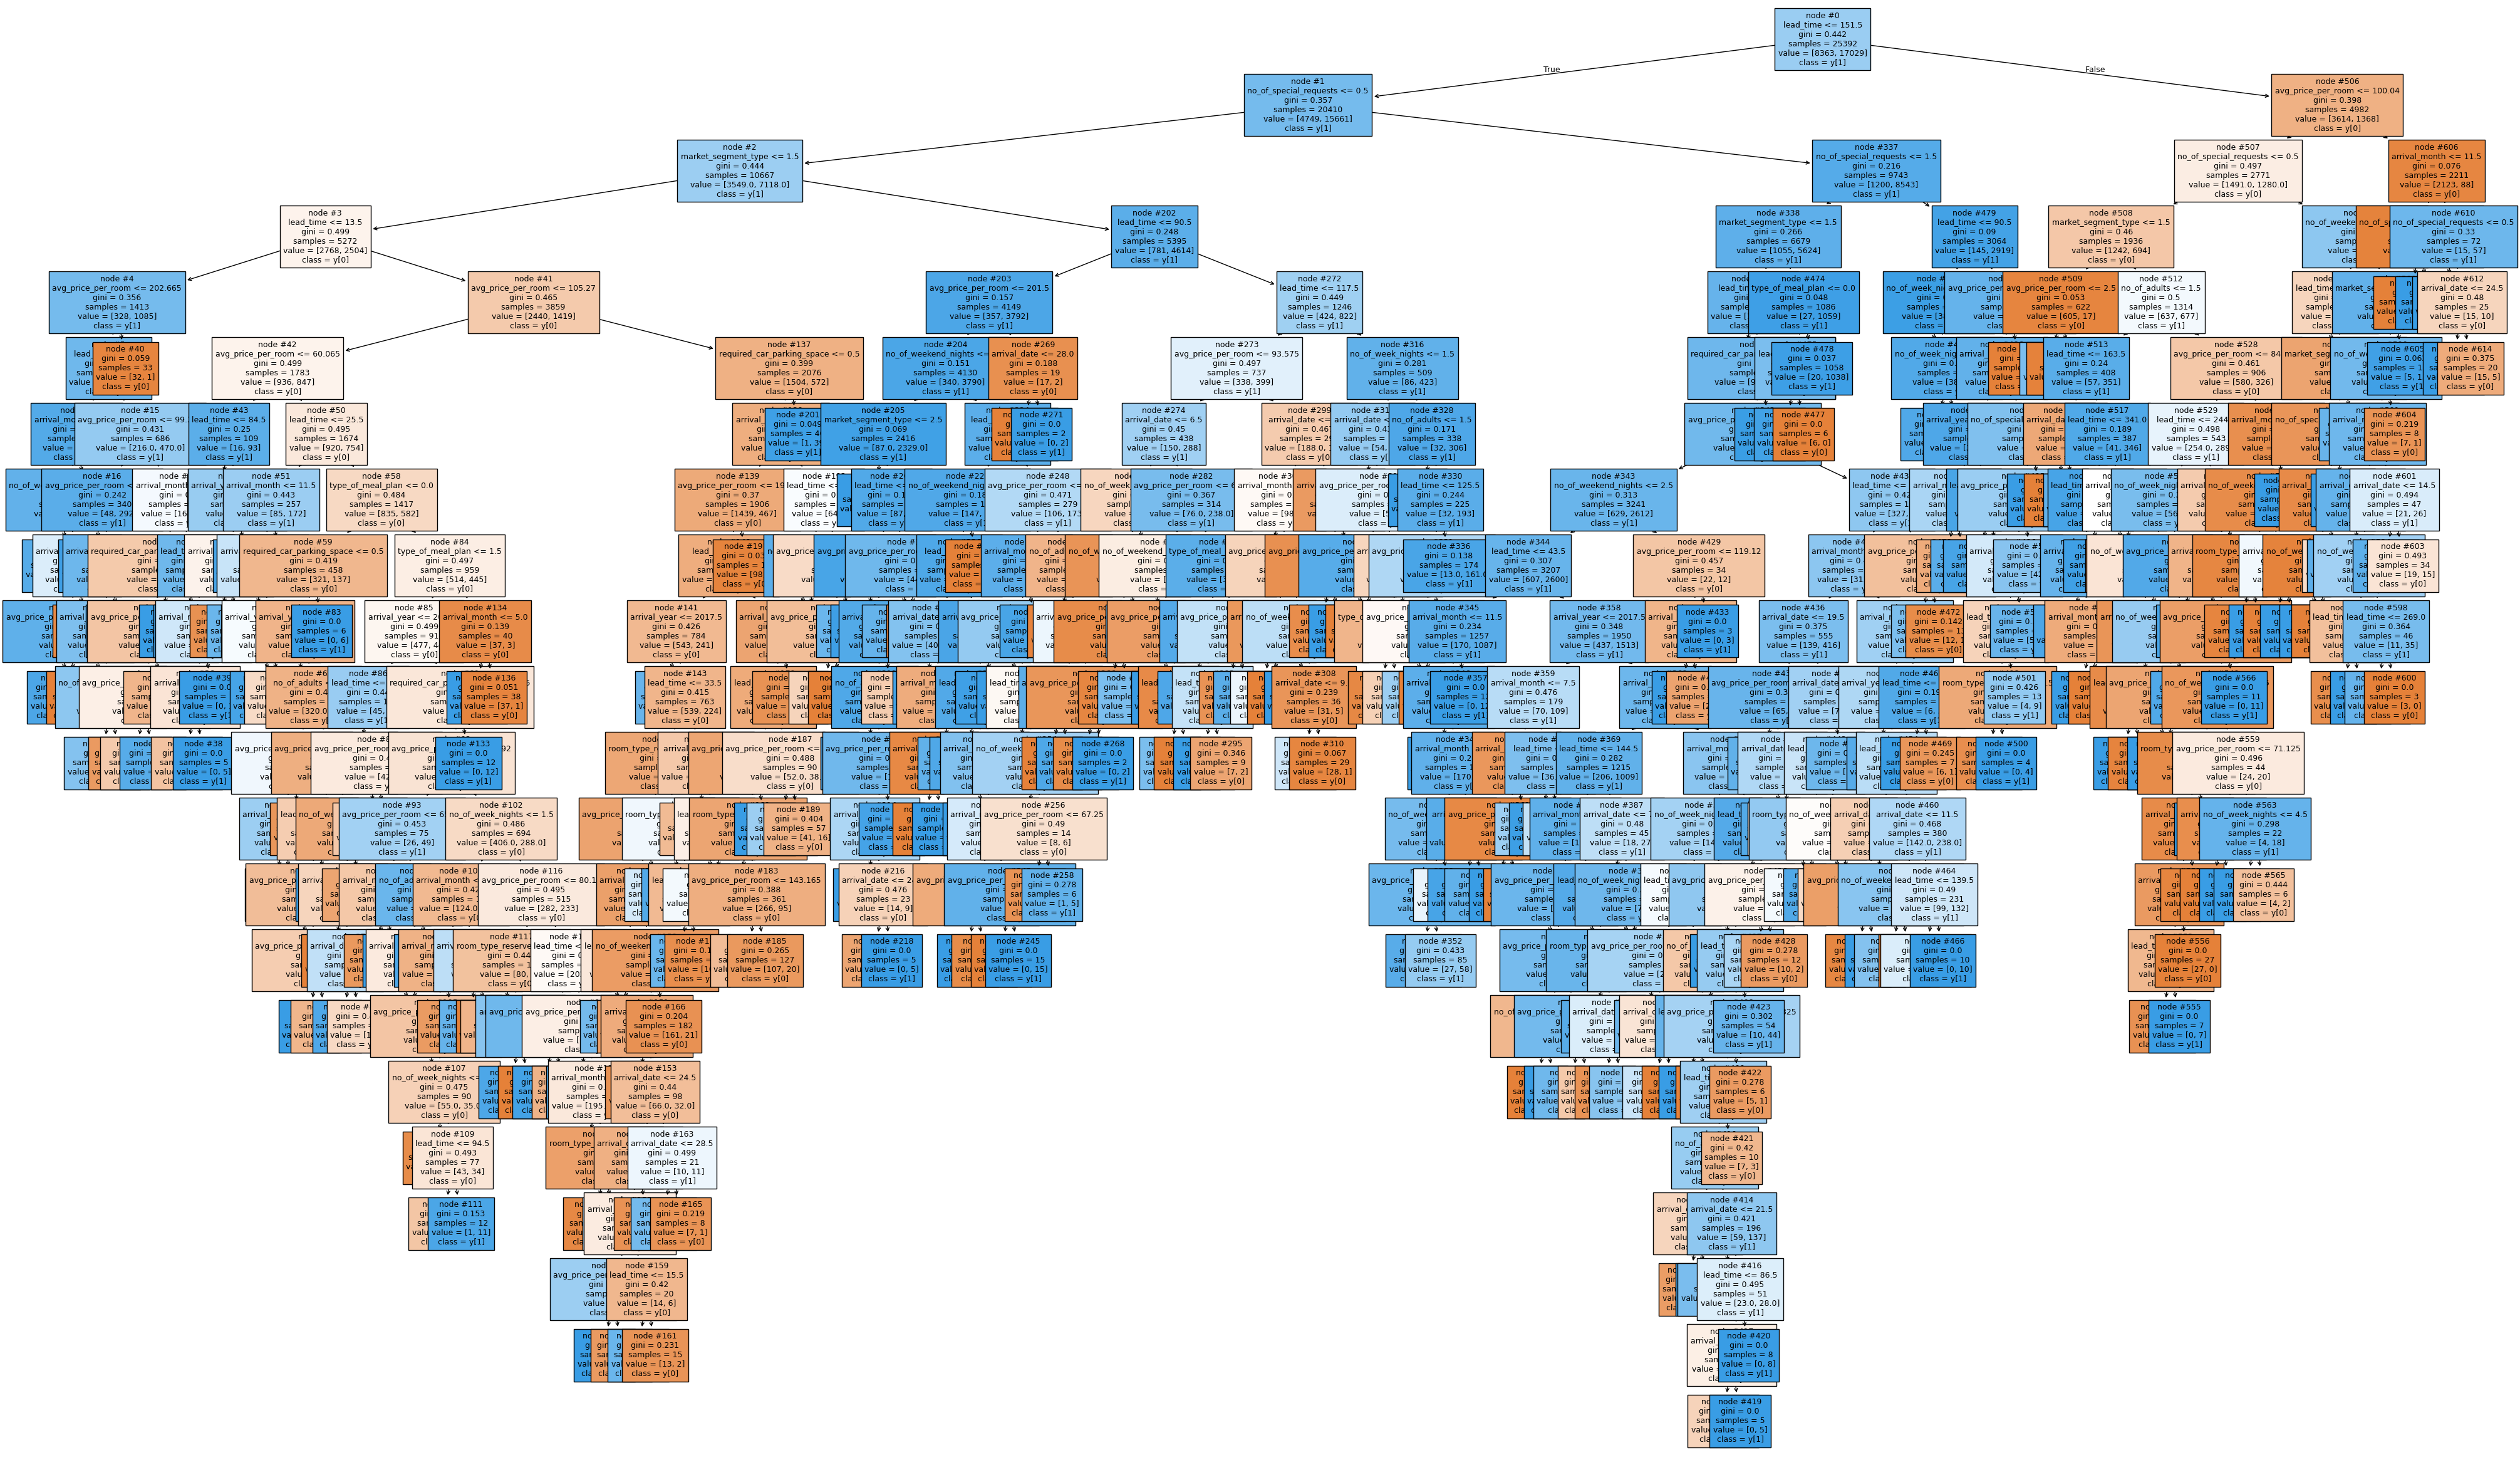

In [112]:
plt.figure(figsize = (50,30))
tree.plot_tree(best_model, feature_names = feature_names, filled = True, fontsize = 9, node_ids = True, class_names = True);

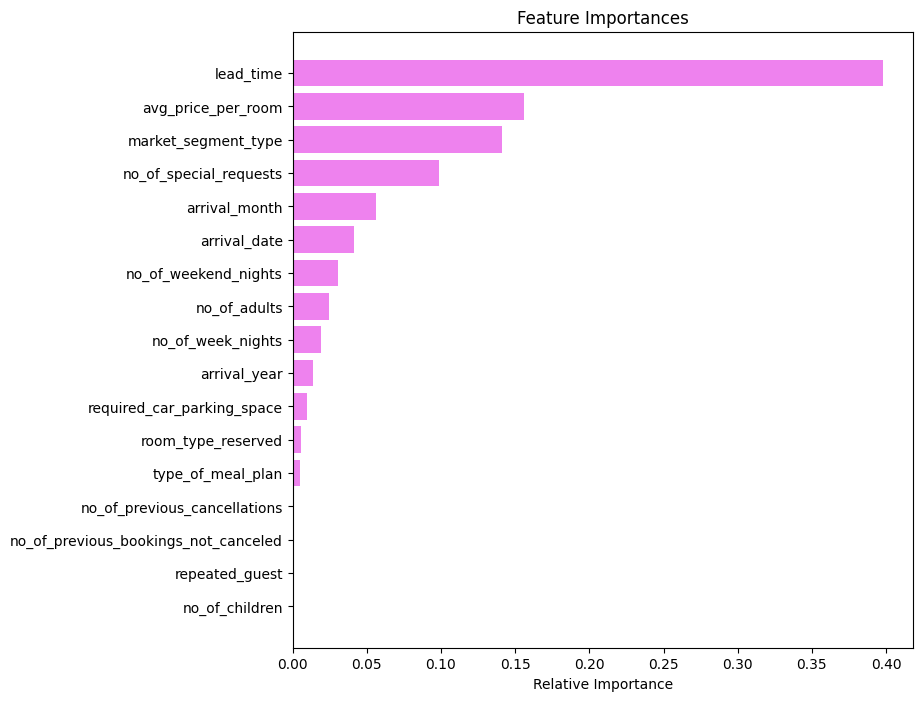

In [105]:
importances = best_model.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(8, 8))
plt.title("Feature Importances")
plt.barh(range(len(indices)), importances[indices], color="violet", align="center")
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Relative Importance")
plt.show()

### Comparison of decision trees

In [106]:
import pandas as pd
from sklearn.metrics import accuracy_score, recall_score

def get_metrics(model):
    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)

    train_acc = accuracy_score(y_train, pred_train)
    test_acc = accuracy_score(y_test, pred_test)
    train_rec = recall_score(y_train, pred_train)
    test_rec = recall_score(y_test, pred_test)

    return train_acc, test_acc, train_rec, test_rec

# Gather scores
models = {
    'Initial decision tree model': dTree,
    'Decision tree with restricted maximum depth': dTree1,
    'Decision tree with hyperparameter tuning': clf,
    'Decision tree with post pruning': best_model
}

data_comparison = []
for name, model in models.items():
    tr_acc, te_acc, tr_rec, te_rec = get_metrics(model)
    data_comparison.append({
        'Model': name,
        'Train Accuracy': tr_acc,
        'Test Accuracy': te_acc,
        'Train Recall': tr_rec,
        'Test Recall': te_rec
    })

comparison_frame = pd.DataFrame(data_comparison)
comparison_frame

,Model,Train Accuracy,Test Accuracy,Train Recall,Test Recall
0,Initial decision tree model,0.99421,0.86971,0.99577,0.89743
1,Decision tree with restricted maximum depth,0.78442,0.79133,0.81038,0.81660
2,Decision tree with hyperparameter tuning,0.82416,0.82753,0.89136,0.89363
3,Decision tree with post pruning,0.90162,0.88330,0.94004,0.92705
